# Humano ou IA? Identificação de autoria textual em português

**Disciplinas:** Processamento de Linguagem Natural · Projeto Integrador
**Instituição:** Faculdade de Tecnologia de Jundiaí (FATEC Jundiaí) · Curso de Ciência de Dados
**Autores:** Allan Vytor Francisco Oliveira · Gabriel Passos · Guilherme Cavalcante Tenório
**Professor(es):** Leonardo de Lellis Rossi &nbsp;|&nbsp; **Data:** 02/11/2026

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SEU_USUARIO/SEU_REPO/blob/main/pipeline_autoria_humano_vs_ia.ipynb)

---

## Problema
Características textuais permitem distinguir textos escritos por pessoas de textos gerados por modelos de linguagem?

**Escopo:** o objetivo **não** é construir um detector universal ou infalível. Queremos medir **até que ponto** classificadores conseguem separar as duas classes **dentro das condições experimentais definidas aqui**, e **onde** eles deixam de funcionar.

## Perguntas de pesquisa
1. **PQ1.** Atributos estilométricos e TF-IDF (palavras e caracteres) já separam humano de IA? Um Transformer (BERTimbau) separa melhor?
2. **PQ2.** Existem padrões de escrita (diversidade lexical, conectivos, legibilidade, estrutura das frases) associados a cada classe?
3. **PQ3.** Um detector treinado com textos de **um** modelo gerador funciona com textos de **outro**, inclusive de um modelo comercial grande (Gemini) nunca visto? E com outro domínio ou com textos curtos/ruidosos?

## Correspondência com o enunciado
| Item do enunciado | Onde é atendido |
|---|---|
| 8.2 Corpus balanceado (Wikipedia + notícias × IA, mesmos temas, tamanhos e gêneros) | Etapas 2 a 5 |
| 8.3.1 Estilometria, n-gramas, TF-IDF + SVM, Random Forest, Regressão Logística | Etapa 7 |
| 8.3.2 Fine-tuning do BERTimbau como classificador binário | Etapa 9 |
| 8.3.3 Accuracy, Precision, Recall, F1, ROC-AUC | Etapas 6, 10 e 11 |
| 8.4 Padrões de escrita, atributos relevantes, clustering, visualização | Etapas 8, 9.3 e 12 |
| 8.4 Treinar com um gerador e testar com outro | Etapa 11 |
| 8.5 Plataforma de análise de autoria | Etapa 13 (`app.py`) |

## O pipeline, de ponta a ponta

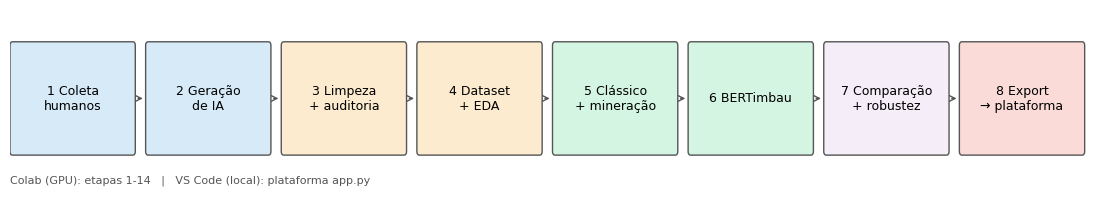

In [ ]:
# Diagrama do pipeline (somente visual)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

etapas = ["1 Coleta\nhumanos", "2 Geração\nde IA", "3 Limpeza\n+ auditoria", "4 Dataset\n+ EDA",
          "5 Clássico\n+ mineração", "6 BERTimbau", "7 Comparação\n+ robustez", "8 Export\n→ plataforma"]
cores = ["#d6eaf8", "#d6eaf8", "#fdebd0", "#fdebd0", "#d5f5e3", "#d5f5e3", "#f5eef8", "#fadbd8"]
fig, ax = plt.subplots(figsize=(14, 2.3)); ax.axis("off"); ax.set_xlim(0, 8.4); ax.set_ylim(0, 1)
for i, (e, c) in enumerate(zip(etapas, cores)):
    ax.add_patch(FancyBboxPatch((i * 1.05 + .02, .2), .93, .6, boxstyle="round,pad=0.02", fc=c, ec="#555"))
    ax.text(i * 1.05 + .485, .5, e, ha="center", va="center", fontsize=9)
    if i < len(etapas) - 1:
        ax.annotate("", xy=((i + 1) * 1.05, .5), xytext=(i * 1.05 + .97, .5), arrowprops=dict(arrowstyle="->", color="#555"))
ax.text(0, .02, "Colab (GPU): etapas 1-14   |   VS Code (local): plataforma app.py", fontsize=8, color="#555")
plt.show()

## Agenda
| Etapa | Conteúdo | Pergunta que responde |
|---|---|---|
| 1 | Ambiente, parâmetros e módulo compartilhado | Como garantir reprodutibilidade? |
| 2 | Coleta dos textos humanos (Wikipedia e portais de notícias `.br`) | De onde vêm os textos humanos? |
| 3 | Geração dos textos de IA (2 modelos abertos, mesmos temas) | Como evitar que o modelo aprenda "assunto"? |
| 4 | **Limpeza e controle de qualidade** (com auditoria) | Quanto do dado bruto sobrevive, e por quê? |
| 5 | Dataset final e análise exploratória | O corpus está balanceado e livre de atalhos? |
| 6 | Divisão treino/validação/teste e métricas | Como avaliar sem vazamento? |
| 7 | Abordagem clássica (estilometria, TF-IDF de palavras e de caracteres; LR, RF, SVM) | PQ1 |
| 8 | Mineração de dados: padrões de escrita, clustering, visualização | PQ2 |
| 9 | Deep learning: fine-tuning do BERTimbau | PQ1 |
| 10 | Comparação dos modelos | PQ1 |
| 11 | Generalização: outro gerador (inclusive Gemini), outro domínio, texto curto/ruidoso | **PQ3** |
| 12 | Análise de erros e interpretabilidade | Onde e por que erramos? |
| 13 | Plataforma (`app.py`) e exportação dos artefatos | Como levar o modelo ao usuário? |
| 14 | Conclusões, limitações e ética | O que concluímos (e o que não)? |

---
# Etapa 1 · Ambiente, parâmetros e módulo compartilhado

**Objetivo:** deixar tudo configurável em um só lugar e criar **um único módulo de texto** (`stylometry.py`) usado no treino **e** na plataforma, para que o texto analisado no app seja tratado exatamente como no treino.

In [ ]:
# 1.1 Instalação
!pip -q install -U datasets accelerate scipy joblib google-genai 2>&1 | grep -v "dependency\|requires" || true

In [ ]:
# 1.2 Imports
import os, re, gc, sys, json, math, random, shutil, time, warnings, unicodedata
from collections import Counter
from datetime import datetime
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, joblib, sklearn, scipy
from scipy.stats import mannwhitneyu
from tqdm.auto import tqdm
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, adjusted_rand_score, normalized_mutual_info_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

import transformers
from transformers import (AutoTokenizer, AutoModel, AutoModelForCausalLM,
                          AutoModelForSequenceClassification, get_linear_schedule_with_warmup)
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "sem GPU: ative em Ambiente de execução > Alterar tipo > GPU")

Dispositivo: cuda | Tesla T4


### 1.3 Módulo compartilhado `stylometry.py`
Contém o **pré-processamento simétrico** (aplicado igualmente a humanos e IA) e os **atributos estilométricos** (tamanho de frases e palavras, riqueza vocabular, pontuação, stopwords, conectivos, legibilidade Flesch-PT, repetição de n-gramas). A célula grava o arquivo e o importa; na Etapa 13 ele é copiado para a plataforma.

Travessões (`—`, `–`) são convertidos para `-`: LLMs usam muito o travessão tipográfico, e sem essa normalização o classificador poderia aprender um **atalho de formatação** em vez de estilo.

In [ ]:
%%writefile stylometry.py
"""
stylometry.py - pré-processamento e atributos estilométricos para PT-BR.

Projeto: Humano ou IA? Identificação de autoria textual em português (FATEC Jundiaí)
Autores: Allan Vytor Francisco Oliveira, Gabriel Passos, Guilherme Cavalcante Tenório

Este módulo é usado tanto no notebook (treino) quanto na plataforma (app.py).
Manter UM único código garante que o texto analisado no app seja tratado
exatamente como foi tratado no treino.
"""
import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd

TRUNC_WORDS = 100            # tamanho (em palavras) dos textos usados no treino
NORMALIZE_TYPOGRAPHY = True  # aspas, reticências e travessões tipográficos -> ASCII (evita "atalhos" de formatação)

# ----------------------------------------------------------------------
# Utilidades básicas
# ----------------------------------------------------------------------
def normalize_ws(t):
    return re.sub(r"\s+", " ", str(t)).strip()

def split_sentences(t):
    return [s for s in re.split(r"(?<=[.!?])\s+", t) if s.strip()]

def n_words(t):
    return len(str(t).split())

def first_n_words(t, n):
    return " ".join(str(t).split()[:n])

def windows(text, size=TRUNC_WORDS, min_last=50):
    """Divide um texto em janelas de `size` palavras (a última só entra se tiver >= min_last)."""
    words = str(text).split()
    if len(words) <= size:
        return [" ".join(words)]
    chunks = [" ".join(words[i:i + size]) for i in range(0, len(words), size)]
    if len(chunks) > 1 and len(chunks[-1].split()) < min_last:
        chunks = chunks[:-1]
    return chunks

# ----------------------------------------------------------------------
# Pré-processamento SIMÉTRICO (aplicado igualmente a textos humanos e de IA)
# ----------------------------------------------------------------------
_URL_RE = re.compile(r"https?://\S+|www\.\S+")
_EMAIL_RE = re.compile(r"\S+@\S+\.\S+")
_CITE_RE = re.compile(r"\[\s*(\d+|nota \d+|carece de fontes|citation needed)\s*\]", re.I)
_EMOJI_RE = re.compile("[\U0001F300-\U0001FAFF☀-➿\U0001F000-\U0001F2FF]+")
_INVIS_RE = re.compile("[​‌‍﻿­]")
_MD_RE = re.compile(r"[*#`_>]+")
_TYPO = str.maketrans({"“": '"', "”": '"', "‘": "'", "’": "'",
                       "«": '"', "»": '"', "…": "...",
                       "—": "-", "–": "-"})

def preprocess(t):
    """Normaliza Unicode, remove URLs/e-mails/citações/emojis/markdown e padroniza aspas e travessões."""
    t = unicodedata.normalize("NFC", str(t))
    t = _INVIS_RE.sub("", t)
    for rx in (_URL_RE, _EMAIL_RE, _CITE_RE, _EMOJI_RE):
        t = rx.sub(" ", t)
    if NORMALIZE_TYPOGRAPHY:
        t = t.translate(_TYPO)
    t = _MD_RE.sub(" ", t)
    return normalize_ws(t)

# ----------------------------------------------------------------------
# Léxicos
# ----------------------------------------------------------------------
STOP_PT = set("a o as os de da do das dos em no na nos nas um uma uns umas e ou mas que se com por para como mais "
              "ao à aos às é são foi ser sua seu suas seus não já também entre sobre até mesmo ela ele eles elas "
              "isso este esta esse essa".split())

CONNECTIVES = ["portanto", "além disso", "entretanto", "no entanto", "contudo", "todavia", "por outro lado",
               "ademais", "dessa forma", "desse modo", "dessa maneira", "assim", "ou seja", "em suma", "por fim",
               "em resumo", "em conclusão", "por exemplo", "porém", "logo", "de fato", "com isso",
               "consequentemente", "sobretudo", "por isso", "em contrapartida"]
# Hipótese testável: LLMs usam mais marcadores de ênfase/valoração
EMPHASIS = ["é importante", "é fundamental", "vale destacar", "vale ressaltar", "é essencial",
            "desempenha um papel", "papel fundamental", "papel importante", "diversos aspectos"]

def _phrase_re(items):
    return re.compile(r"\b(" + "|".join(re.escape(x) for x in sorted(items, key=len, reverse=True)) + r")\b")

_CONN_RE = _phrase_re(CONNECTIVES)
_EMPH_RE = _phrase_re(EMPHASIS)

# ----------------------------------------------------------------------
# Silabação aproximada e legibilidade (Flesch adaptado ao português)
# ----------------------------------------------------------------------
_VOW_GROUP = re.compile(r"[aeiouáéíóúâêôãõàü]+")
_STRONG = re.compile(r"[aeoáéóâêôãõ]")

def count_syllables_pt(word):
    """Aproximação: cada grupo vocálico = 1 sílaba; vogais fortes consecutivas (a/e/o) formam hiato."""
    n = 0
    for g in _VOW_GROUP.findall(word.lower()):
        n += max(1, len(_STRONG.findall(g)))
    return max(n, 1)

def flesch_pt(n_words_, n_sents, n_syll):
    """Índice de Facilidade de Leitura Flesch adaptado ao português (Martins et al., 1996)."""
    if n_words_ == 0 or n_sents == 0:
        return 0.0
    return 248.835 - 1.015 * (n_words_ / n_sents) - 84.6 * (n_syll / n_words_)

# ----------------------------------------------------------------------
# Atributos estilométricos
# ----------------------------------------------------------------------
def stylo_features(t):
    t = str(t)
    words = re.findall(r"\w+", t.lower())
    nw = max(len(words), 1)
    sents = split_sentences(t) or [t]
    sl = np.array([len(re.findall(r"\w+", s)) for s in sents], dtype=float)
    bi = list(zip(words, words[1:]))
    tri = list(zip(words, words[1:], words[2:]))
    cnt = Counter(words)
    syl = sum(count_syllables_pt(w) for w in words)
    low = t.lower()
    L = max(len(t), 1)
    return {
        "st_n_sents": len(sents),
        "st_avg_sent_len": sl.mean(),
        "st_std_sent_len": sl.std(),
        "st_cv_sent_len": sl.std() / (sl.mean() + 1e-9),
        "st_max_sent_len": sl.max(),
        "st_avg_word_len": float(np.mean([len(w) for w in words])) if words else 0.0,
        "st_long_word_ratio": float(np.mean([len(w) >= 9 for w in words])) if words else 0.0,
        "st_ttr": len(cnt) / nw,
        "st_hapax_ratio": sum(1 for c in cnt.values() if c == 1) / nw,
        "st_stop_ratio": sum(w in STOP_PT for w in words) / nw,
        "st_connectives": 100 * len(_CONN_RE.findall(low)) / nw,
        "st_emphasis": 100 * len(_EMPH_RE.findall(low)) / nw,
        "st_flesch": flesch_pt(len(words), len(sents), syl),
        "st_syll_per_word": syl / nw,
        "st_comma": t.count(",") / nw,
        "st_period": t.count(".") / nw,
        "st_colon_semicolon": (t.count(":") + t.count(";")) / nw,
        "st_excl_quest": (t.count("!") + t.count("?")) / nw,
        "st_quotes_parens": sum(t.count(c) for c in '"()') / nw,
        "st_dash": t.count(" - ") / nw,
        "st_digit_ratio": sum(c.isdigit() for c in t) / L,
        "st_upper_ratio": sum(c.isupper() for c in t) / L,
        "st_rep_bigram": 1 - len(set(bi)) / max(len(bi), 1),
        "st_rep_trigram": 1 - len(set(tri)) / max(len(tri), 1),
    }

FEATURE_COLS = list(stylo_features("Exemplo de texto. Outra frase aqui, com vírgula.").keys())

FEATURE_LABELS = {
    "st_n_sents": "Nº de frases",
    "st_avg_sent_len": "Tamanho médio da frase (palavras)",
    "st_std_sent_len": "Desvio do tamanho das frases",
    "st_cv_sent_len": "Variação relativa do tamanho das frases",
    "st_max_sent_len": "Maior frase (palavras)",
    "st_avg_word_len": "Tamanho médio da palavra (letras)",
    "st_long_word_ratio": "Proporção de palavras longas (>=9 letras)",
    "st_ttr": "Riqueza vocabular (type-token ratio)",
    "st_hapax_ratio": "Palavras que aparecem uma só vez",
    "st_stop_ratio": "Proporção de stopwords",
    "st_connectives": "Conectivos (por 100 palavras)",
    "st_emphasis": "Marcadores de ênfase (por 100 palavras)",
    "st_flesch": "Legibilidade (Flesch-PT; maior = mais fácil)",
    "st_syll_per_word": "Sílabas por palavra (aprox.)",
    "st_comma": "Vírgulas por palavra",
    "st_period": "Pontos por palavra",
    "st_colon_semicolon": "Dois-pontos e ponto e vírgula por palavra",
    "st_excl_quest": "Exclamações e interrogações por palavra",
    "st_quotes_parens": "Aspas e parênteses por palavra",
    "st_dash": "Travessões ( - ) por palavra",
    "st_digit_ratio": "Proporção de dígitos",
    "st_upper_ratio": "Proporção de maiúsculas",
    "st_rep_bigram": "Repetição de bigramas",
    "st_rep_trigram": "Repetição de trigramas",
}

def build_features(texts):
    """DataFrame (uma linha por texto) com os atributos estilométricos, na ordem de FEATURE_COLS."""
    return pd.DataFrame([stylo_features(t) for t in texts])[FEATURE_COLS]

Writing stylometry.py


In [ ]:
# Importa o módulo recém-gravado
sys.path.insert(0, os.getcwd())
import importlib, stylometry
importlib.reload(stylometry)
from stylometry import (TRUNC_WORDS, normalize_ws, split_sentences, n_words, first_n_words, windows, preprocess,
                        STOP_PT, CONNECTIVES, FEATURE_COLS, FEATURE_LABELS, build_features, stylo_features)
print(f"Atributos estilométricos: {len(FEATURE_COLS)} | tamanho-alvo dos textos: {TRUNC_WORDS} palavras")

Atributos estilométricos: 24 | tamanho-alvo dos textos: 100 palavras


### 1.4 Parâmetros do experimento

In [ ]:
# 1.4 Parâmetros
QUICK_MODE   = False                       # True = ensaio rápido com poucos dados (rode assim primeiro)
N_PER_DOMAIN = 40 if QUICK_MODE else 300   # pares humano/IA desejados por domínio (após a limpeza)
OVERSAMPLE   = 1.15                        # coletamos um pouco a mais, pois a limpeza descarta textos
RAW_WORDS    = 300                         # palavras guardadas no texto bruto (a limpeza corta em TRUNC_WORDS)
MIN_WORDS    = TRUNC_WORDS                 # mínimo de palavras para um texto entrar no corpus
MAX_NEW_TOKENS, GEN_BATCH = 320, 16        # geração (reduza GEN_BATCH se faltar memória de GPU)
DOMAINS      = ("wiki", "noticias")        # domínios humanos: Wikipedia PT e portais de notícias brasileiros
NEWS_SCAN_LIMIT = 300_000 if QUICK_MODE else 2_000_000   # documentos da web varridos à procura de notícias

# Geradores de IA usados no TREINO (modelos abertos, sem token do Hugging Face). Se o Phi der erro na sua versão
# do transformers, troque por "Qwen/Qwen2.5-3B-Instruct" (mas ficarão da mesma família: enfraquece a PQ3).
GENERATORS = {"qwen": "Qwen/Qwen2.5-1.5B-Instruct", "phi": "microsoft/Phi-3.5-mini-instruct"}

# Gerador EXTERNO, usado SÓ NO TESTE (11.4): modelo comercial grande, nunca visto no treino.
RUN_EXTERNAL = True
GEMINI_MODEL = "gemini-2.5-flash"          # se o nome mudar, veja os modelos disponíveis em aistudio.google.com

BERT_MODEL = "neuralmind/bert-base-portuguese-cased"   # BERTimbau base
BERT_MAX_LEN = 192

USE_DRIVE = True   # True: salva tudo no Google Drive (recomendado, sobrevive a quedas de sessão)
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJ = "/content/drive/MyDrive/autoria_humano_vs_ia"
else:
    PROJ = "/content/autoria_humano_vs_ia"
for sub in ["data", "figs", "export"]:
    os.makedirs(os.path.join(PROJ, sub), exist_ok=True)

RAW_PATH = os.path.join(PROJ, "data", f"dataset_bruto_n{N_PER_DOMAIN}.csv")
LOAD_RAW = os.path.exists(RAW_PATH)
print("Projeto em:", PROJ, "| dataset bruto já existe?", LOAD_RAW)

def savefig(name):
    plt.savefig(os.path.join(PROJ, "figs", f"{name}.png"), dpi=200, bbox_inches="tight")

Mounted at /content/drive
Projeto em: /content/drive/MyDrive/autoria_humano_vs_ia | dataset bruto já existe? True


---
# Etapa 2 · Coleta dos textos humanos

**Objetivo:** reunir textos escritos por pessoas, em português, de duas fontes públicas.

| Fonte | Papel | Gênero |
|---|---|---|
| **Wikipedia PT** (`wikimedia/wikipedia`) | fonte principal | enciclopédico |
| **Notícias brasileiras** (FineWeb-2, filtrado por portais jornalísticos) | segundo domínio, usado também para testar generalização | jornalístico |

Guardamos o texto **bruto** (até 300 palavras) e o **tema** de cada documento. A limpeza pesada acontece na Etapa 4, de forma auditável.

In [ ]:
# 2.1 Wikipedia PT
from datasets import load_dataset

def collect_wikipedia(n):
    ds = load_dataset("wikimedia/wikipedia", "20231101.pt", split="train", streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=10_000)
    out, seen, pbar = [], set(), tqdm(total=n, desc="Wikipedia")
    for ex in ds:
        title, tl = ex["title"], ex["title"].lower()
        if "desambigu" in tl or tl.startswith(("lista de", "anexo", "categoria")):
            continue
        lines = [l.strip() for l in ex["text"].split("\n") if n_words(l) >= 12]   # descarta títulos de seção
        body = normalize_ws(" ".join(lines))
        if n_words(body) < MIN_WORDS or body[:60] in seen:
            continue
        seen.add(body[:60])
        out.append({"domain": "wiki", "topic": title, "raw_text": first_n_words(body, RAW_WORDS)})
        pbar.update(1)
        if len(out) >= n: break
    pbar.close(); return out

N_COLLECT = int(N_PER_DOMAIN * OVERSAMPLE)
wiki_rows = [] if LOAD_RAW else collect_wikipedia(N_COLLECT)
print(len(wiki_rows), "textos da Wikipedia coletados")

0 textos da Wikipedia coletados


In [ ]:
# 2.2 Notícias brasileiras (FineWeb-2 filtrado por portais jornalísticos)
NEWS_DOMAINS = [
    "g1.globo.com", "oglobo.globo.com", "valor.globo.com", "folha.uol.com.br", "noticias.uol.com.br",
    "economia.uol.com.br", "estadao.com.br", "cnnbrasil.com.br", "agenciabrasil.ebc.com.br", "r7.com",
    "terra.com.br", "metropoles.com", "correiobraziliense.com.br", "gazetadopovo.com.br", "em.com.br",
    "otempo.com.br", "gauchazh.clicrbs.com.br", "band.uol.com.br", "poder360.com.br", "exame.com",
    "veja.abril.com.br", "istoe.com.br", "cartacapital.com.br", "infomoney.com.br", "opovo.com.br",
    "diariodepernambuco.com.br", "jc.ne10.uol.com.br", "atarde.com.br", "correio24horas.com.br",
    "acritica.com", "nsctotal.com.br", "jornaldebrasilia.com.br", "diariodonordeste.verdesmares.com.br",
    "odia.ig.com.br", "extra.globo.com", "jornaldocomercio.com", "tribunaonline.com.br", "campograndenews.com.br",
]
_NEWS_PATH = re.compile(r"/noticias?(/|-|\.)|/news/|/ultimas-noticias")

def is_news(url):
    u = urlparse(url or ""); host = u.netloc.lower().removeprefix("www.")
    if any(host == d or host.endswith("." + d) for d in NEWS_DOMAINS):
        return True
    return host.endswith(".br") and bool(_NEWS_PATH.search(u.path.lower()))   # outros sites .br com seção de notícias

def collect_news(n, scan_limit=NEWS_SCAN_LIMIT):
    ds = load_dataset("HuggingFaceFW/fineweb-2", name="por_Latn", split="train", streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=10_000)
    out, seen, pbar = [], set(), tqdm(total=n, desc="Notícias .br")
    for i, ex in enumerate(ds):
        if i >= scan_limit or len(out) >= n: break
        if not is_news(ex.get("url", "")): continue
        paras = [normalize_ws(p) for p in ex["text"].split("\n") if n_words(p) >= 8]   # descarta menus/botões
        sents = split_sentences(" ".join(paras))
        if len(sents) < 4: continue
        topic, rest = sents[0], " ".join(sents[1:])       # 1ª frase (manchete/lide) vira o tema do prompt e sai do texto
        if not (4 <= n_words(topic) <= 35) or n_words(rest) < MIN_WORDS or rest[:60] in seen: continue
        seen.add(rest[:60])
        out.append({"domain": "noticias", "topic": topic, "raw_text": first_n_words(rest, RAW_WORDS), "url": ex.get("url", "")})
        pbar.update(1)
    pbar.close()
    if len(out) < n:
        print(f"Só {len(out)} notícias em {scan_limit:,} documentos. Aumente NEWS_SCAN_LIMIT se quiser mais "
              f"(o corpus continua balanceado: cada notícia tem o seu par de IA).")
    return out

news_rows = [] if LOAD_RAW else collect_news(N_COLLECT)
print(len(news_rows), "notícias coletadas")
if news_rows:
    print("Portais mais frequentes:", Counter(urlparse(r["url"]).netloc for r in news_rows).most_common(8))
if not LOAD_RAW:
    assert wiki_rows and news_rows, "Falha na coleta: verifique a conexão e os nomes dos datasets."

0 notícias coletadas


---
# Etapa 3 · Geração dos textos de IA

**Objetivo:** para **cada texto humano** gerar **um** texto de IA **sobre o mesmo tema e no mesmo gênero**. Assim o classificador não consegue "trapacear" aprendendo assunto, e o corpus nasce **pareado** (1 humano ↔ 1 IA).

- Dois geradores de famílias diferentes (**Qwen2.5-1.5B** e **Phi-3.5-mini**), alternados: cada um escreve metade dos textos de cada domínio. Isso permite a pergunta central da PQ3: *treinar com um, testar no outro*.
- Prompt padronizado por domínio (verbete de enciclopédia ou notícia), pedindo texto corrido, ~150 palavras, sem título/markdown. Amostragem com `temperature=0.8`.
- Um terceiro gerador, comercial e bem maior (**Gemini**), é usado **apenas no teste** (Etapa 11.4).

In [ ]:
# 3.1 Prompts e atribuição de gerador
PROMPT_TEMPLATES = {
    "wiki": 'Escreva o início de um verbete de enciclopédia, em português, sobre o tema: "{topic}". '
            'Escreva cerca de 150 palavras, em um único parágrafo, sem título, sem listas e sem '
            'formatação markdown. Responda apenas com o texto.',
    "noticias": 'Escreva uma notícia jornalística em português do Brasil a partir da seguinte manchete ou lide: "{topic}". '
                'Escreva cerca de 150 palavras, em texto corrido, sem título, sem listas e sem '
                'formatação markdown. Responda apenas com o texto da notícia.',
}
SYSTEM_PROMPT = "Você é um assistente prestativo que escreve em português do Brasil."

if not LOAD_RAW:
    humans = pd.DataFrame(wiki_rows + news_rows).drop(columns="url", errors="ignore").reset_index(drop=True)
    humans["topic_id"] = humans.index
    humans["group"] = humans.domain + "_" + humans.topic_id.astype(str)
    humans["generator"] = np.where(humans.groupby("domain").cumcount() % 2 == 0, "qwen", "phi")
    print(humans.groupby(["domain", "generator"]).size().unstack())

In [ ]:
# 3.2 Funções de geração
def load_generator(name):
    tok = AutoTokenizer.from_pretrained(name, padding_side="left")
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(
        name, torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32).to(DEVICE).eval()
    return tok, model

@torch.no_grad()
def generate_texts(tok, model, prompts, max_new_tokens=MAX_NEW_TOKENS, batch=GEN_BATCH, temperature=0.8, top_p=0.95):
    outs = []
    for i in tqdm(range(0, len(prompts), batch), desc="Gerando"):
        chats = [tok.apply_chat_template([{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": p}],
                                         tokenize=False, add_generation_prompt=True) for p in prompts[i:i + batch]]
        enc = tok(chats, return_tensors="pt", padding=True).to(DEVICE)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=True, temperature=temperature,
                             top_p=top_p, pad_token_id=tok.pad_token_id)
        outs += tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return outs

def run_generator(key):
    path = os.path.join(PROJ, "data", f"geracao_{key}_n{N_PER_DOMAIN}.csv")     # cache por gerador
    if os.path.exists(path): return pd.read_csv(path)
    sub = humans[humans.generator == key]
    prompts = [PROMPT_TEMPLATES[d].format(topic=t.replace('"', "'")) for d, t in zip(sub.domain, sub.topic)]
    tok, model = load_generator(GENERATORS[key])
    outs = generate_texts(tok, model, prompts)
    del model, tok; gc.collect(); torch.cuda.empty_cache()
    res = pd.DataFrame({"topic_id": sub.topic_id.values, "raw_text": outs, "generator": key})
    res.to_csv(path, index=False); return res

In [ ]:
# 3.3 Gerador A: Qwen2.5-1.5B-Instruct  (~5-10 min)
ai_qwen = None if LOAD_RAW else run_generator("qwen")
if ai_qwen is not None: print(ai_qwen.raw_text.iloc[0][:600])

In [ ]:
# 3.4 Gerador B: Phi-3.5-mini-instruct  (~10-20 min)
ai_phi = None if LOAD_RAW else run_generator("phi")
if ai_phi is not None: print(ai_phi.raw_text.iloc[0][:600])

In [ ]:
# 3.5 Monta e SALVA o dataset bruto (rastreabilidade: tudo o que veio das fontes, antes de qualquer limpeza)
if LOAD_RAW:
    df_raw = pd.read_csv(RAW_PATH)
else:
    ai = pd.concat([ai_qwen, ai_phi], ignore_index=True)
    ai = ai.merge(humans[["topic_id", "topic", "group", "domain"]], on="topic_id", how="left")
    ai["source"], ai["label"] = ai.generator, 1
    h = humans.assign(source="human", label=0)
    cols = ["group", "domain", "topic_id", "topic", "source", "label", "raw_text"]
    df_raw = pd.concat([h[cols], ai[cols]], ignore_index=True)
    df_raw.to_csv(RAW_PATH, index=False)
print("Dataset BRUTO:", df_raw.shape, "->", RAW_PATH)
display(df_raw.groupby(["domain", "source"]).size().unstack(fill_value=0))

Dataset BRUTO: (1380, 7) -> /content/drive/MyDrive/autoria_humano_vs_ia/data/dataset_bruto_n300.csv


source,human,phi,qwen
domain,,,
noticias,345,172,173
wiki,345,172,173


---
# Etapa 4 · Limpeza e controle de qualidade

**Objetivo:** transformar o dado bruto em um corpus **limpo, comparável e balanceado**, registrando **o que foi removido e por quê**.

**Princípios**
1. **Limpeza simétrica:** a mesma normalização é aplicada a humanos e IA (URLs, e-mails, citações `[1]`, emojis, markdown, aspas e travessões tipográficos). Se só limpássemos um lado, o modelo aprenderia a limpeza, não a autoria.
2. **Tratamento específico só do que é artefato de LLM:** preâmbulos ("Claro! Aqui está…") e títulos.
3. **Filtros de qualidade** com motivo registrado: curto demais, idioma/alfabeto errado, "meta-texto" de LLM (recusas, "como modelo de linguagem…"), caracteres anormais, repetição degenerada, duplicatas.
4. **Corte em exatamente 100 palavras** (controla o tamanho) e **pares completos** (se um lado do par cai, o outro cai também → corpus balanceado por construção).

In [ ]:
# 4.1 Funções de limpeza específicas de artefatos de LLM
def strip_llm_preamble(t):
    # "Claro! Aqui está o texto:", linhas curtas de título etc. (só faz sentido para textos de IA)
    t = re.sub(r"^(claro|certo|com certeza|aqui est[áa]|segue)\b[^\n]{0,80}?[:!]\s*", "", str(t).strip(), flags=re.I)
    lines = [l.strip() for l in t.split("\n") if l.strip()]
    for _ in range(2):
        if len(lines) > 1 and n_words(lines[0]) < 8 and not lines[0].endswith((".", "!", "?")):
            lines = lines[1:]
    return "\n".join(lines)

# 4.2 Filtros de qualidade: cada função devolve True se o texto deve ser DESCARTADO
CJK_RE = re.compile(r"[Ѐ-ӿ֐-ۿ぀-ヿ㐀-鿿가-힯]")   # cirílico, árabe, japonês, chinês, coreano
META_RE = re.compile(r"(como (um|uma) (modelo|assistente|ia|inteligência artificial)|não posso (ajudar|fornecer|escrever|criar|atender)"
                     r"|desculpe|sinto muito|word count|contagem de palavras|\bnota:|\bobservação:|\(\d+ palavras\))", re.I)

def f_curto(t):   return n_words(t) < MIN_WORDS
def f_idioma(t):
    ws = re.findall(r"\w+", t.lower())
    return bool(CJK_RE.search(t)) or (sum(w in STOP_PT for w in ws) / max(len(ws), 1) < 0.20)
def f_meta(t):    return bool(META_RE.search(t))
def f_chars(t):
    # proporção calculada sobre caracteres NÃO-espaço (texto normal em português fica em ~0,93-0,97 de letras)
    cs = [c for c in t if not c.isspace()]; n = max(len(cs), 1)
    return (sum(c.isalpha() for c in cs) / n < 0.85) or (sum(c.isdigit() for c in cs) / n > 0.10)
def f_repeticao(t):
    w = t.lower().split(); tri = Counter(zip(w, w[1:], w[2:]))
    return (len(set(w)) / max(len(w), 1) < 0.30) or bool(tri and max(tri.values()) >= 4)

FILTERS = [("curto_demais", f_curto), ("idioma_ou_alfabeto", f_idioma), ("meta_llm_ou_recusa", f_meta),
           ("caracteres_anormais", f_chars), ("repeticao_degenerada", f_repeticao)]

# 4.3 Quase-duplicatas (Jaccard de shingles de 5 palavras)
def shingles(t, k=5):
    w = t.lower().split(); return {" ".join(w[i:i + k]) for i in range(max(len(w) - k + 1, 1))}
def find_near_dups(texts, thr=0.8):
    sh, dup = [shingles(t) for t in texts], set()
    for i in range(len(sh)):
        if i in dup: continue
        for j in range(i + 1, len(sh)):
            if j not in dup and sh[i] & sh[j] and len(sh[i] & sh[j]) / len(sh[i] | sh[j]) >= thr:
                dup.add(j)
    return dup

In [ ]:
# 4.4 Pipeline de limpeza (devolve TODAS as linhas, com o motivo de descarte quando houver)
def apply_filters(d):
    d["drop_reason"] = None
    for nome, fn in FILTERS:                                             # filtros em sequência
        pend = d.drop_reason.isna()
        hit = d.loc[pend, "text"].map(fn)
        d.loc[hit[hit].index, "drop_reason"] = nome
    return d

def clean_dataframe(raw):
    d = raw.copy().reset_index(drop=True)
    d["text"] = d.raw_text.fillna("").astype(str)
    ia = d.label == 1
    d.loc[ia, "text"] = d.loc[ia, "text"].map(strip_llm_preamble)       # só IA: preâmbulo/título
    d["text"] = d.text.map(preprocess)                                   # simétrico: humanos e IA
    d = apply_filters(d)
    ok = d.drop_reason.isna()
    d.loc[ok, "text"] = d.loc[ok, "text"].map(lambda t: first_n_words(t, TRUNC_WORDS))   # corte em 100 palavras
    for lab in (0, 1):                                                   # duplicatas dentro de cada classe
        idx = d[d.drop_reason.isna() & (d.label == lab)].index
        dup = find_near_dups(d.loc[idx, "text"].tolist())
        d.loc[[idx[i] for i in dup], "drop_reason"] = "duplicata"
    vivos = d[d.drop_reason.isna()].groupby("group").label.nunique()     # pares completos
    quebrados = vivos[vivos < 2].index                                   # o par perdeu um dos lados
    d.loc[d.drop_reason.isna() & d.group.isin(quebrados), "drop_reason"] = "par_incompleto"
    return d

d_clean = clean_dataframe(df_raw)
ORDEM = ["curto_demais", "idioma_ou_alfabeto", "meta_llm_ou_recusa", "caracteres_anormais",
         "repeticao_degenerada", "duplicata", "par_incompleto"]
print("Linhas brutas:", len(d_clean), "| mantidas:", d_clean.drop_reason.isna().sum())

Linhas brutas: 1380 | mantidas: 1106


### 4.5 Auditoria da limpeza
O funil abaixo mostra quantos textos sobraram após cada filtro, por classe. É a evidência de que a limpeza **não é uma caixa-preta**: quem avalia o trabalho consegue ver o que foi descartado.

classe,IA,humano
motivo,,
curto_demais,60,0
idioma_ou_alfabeto,2,13
meta_llm_ou_recusa,19,0
caracteres_anormais,0,4
repeticao_degenerada,3,46
duplicata,0,0
par_incompleto,53,74
MANTIDO,553,553


,humano,IA
etapa,,
bruto,690,690
após 'curto_demais',690,630
após 'idioma_ou_alfabeto',677,628
após 'meta_llm_ou_recusa',677,609
após 'caracteres_anormais',673,609
após 'repeticao_degenerada',627,606
após 'duplicata',627,606
após 'par_incompleto',553,553


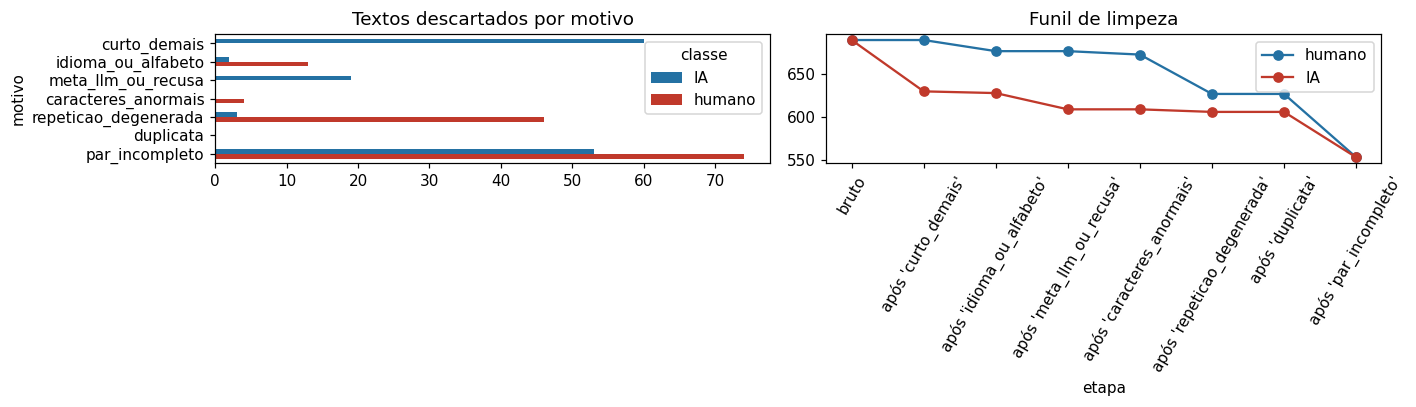

**Resumo:** foram descartados **19.9%** dos textos humanos e **19.9%** dos de IA (o descarte inclui os pares que perderam a outra metade). O motivo mais frequente foi **`par_incompleto`**.

In [ ]:
# 4.5 Auditoria: funil e motivos de descarte
d_clean["classe"] = np.where(d_clean.label == 0, "humano", "IA")
motivos = d_clean.assign(motivo=d_clean.drop_reason.fillna("MANTIDO")).groupby(["motivo", "classe"]).size().unstack(fill_value=0)
motivos = motivos.reindex(ORDEM + ["MANTIDO"]).fillna(0).astype(int)
display(motivos)

funil = [{"etapa": "bruto", "humano": (d_clean.label == 0).sum(), "IA": (d_clean.label == 1).sum()}]
rest = d_clean.copy()
for m in ORDEM:
    rest = rest[rest.drop_reason != m]
    funil.append({"etapa": f"após '{m}'", "humano": (rest.label == 0).sum(), "IA": (rest.label == 1).sum()})
funil = pd.DataFrame(funil).set_index("etapa"); display(funil)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
motivos.drop("MANTIDO").plot.barh(ax=ax[0], color=["#2471a3", "#c0392b"]); ax[0].set_title("Textos descartados por motivo"); ax[0].invert_yaxis()
funil.plot(ax=ax[1], marker="o", color=["#2471a3", "#c0392b"]); ax[1].set_title("Funil de limpeza"); ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); savefig("limpeza_auditoria"); plt.show()

taxa = (1 - motivos.loc["MANTIDO"] / motivos.sum()).round(3)
display(Markdown(f"**Resumo:** foram descartados **{taxa['humano']:.1%}** dos textos humanos e **{taxa['IA']:.1%}** dos de IA "
                 f"(o descarte inclui os pares que perderam a outra metade). O motivo mais frequente foi "
                 f"**`{motivos.drop('MANTIDO').sum(axis=1).idxmax()}`**."))

In [ ]:
# 4.6 Antes e depois (3 textos de IA): o que a limpeza removeu
amostra = d_clean[(d_clean.label == 1)].head(3)
for _, r in amostra.iterrows():
    print(f"--- [{r.source}/{r.domain}] BRUTO:\n{str(r.raw_text)[:350]}\n--- LIMPO ({r.drop_reason or 'mantido'}):\n{r.text[:350]}\n")

--- [qwen/wiki] BRUTO:
Alfonso Capecelatro di Castelpagano (1398-1472) foi um importante político italiano do século XV. Nascido na cidade de Lucca, Capecelatro se destacou no contexto político da Itália Média e do Renascimento. Ele liderou a corte de Luiz XI de França durante sua primeira viagem à Itália, sendo considerado pelo papa Alexandre VI como um dos primeiros di
--- LIMPO (mantido):
Alfonso Capecelatro di Castelpagano (1398-1472) foi um importante político italiano do século XV. Nascido na cidade de Lucca, Capecelatro se destacou no contexto político da Itália Média e do Renascimento. Ele liderou a corte de Luiz XI de França durante sua primeira viagem à Itália, sendo considerado pelo papa Alexandre VI como um dos primeiros di

--- [qwen/wiki] BRUTO:
Nome completo: Remzi Aydin Jöntürk

Remzi Aydin Jöntürk (1921-2008) foi um importante filósofo e teólogo muçulmano turco nascido na Turquia Oriental durante a Segunda Guerra Mundial. Jöntürk desempenhou uma função crucial no movim

In [ ]:
# 4.7 Dataset final limpo + verificações de integridade + ficha do dataset
df = d_clean[d_clean.drop_reason.isna()][["group", "domain", "topic_id", "topic", "source", "label", "text"]].reset_index(drop=True)

assert df.text.map(n_words).eq(TRUNC_WORDS).all(), "todos os textos devem ter exatamente TRUNC_WORDS palavras"
assert df.label.value_counts().nunique() == 1, "classes desbalanceadas"
assert df.groupby("group").label.nunique().eq(2).all(), "há par incompleto"
print(f"Integridade OK: {len(df)} textos = {len(df)//2} pares | {TRUNC_WORDS} palavras cada | classes balanceadas")

CLEAN_PATH = os.path.join(PROJ, "data", "dataset_limpo.csv")
df.to_csv(CLEAN_PATH, index=False)
card = {"nome": "Autoria humano vs IA (PT-BR)", "criado_em": datetime.now().isoformat(timespec="seconds"),
        "autores": ["Allan Vytor Francisco Oliveira", "Gabriel Passos", "Guilherme Cavalcante Tenório"],
        "fontes_humanas": {"wiki": "wikimedia/wikipedia 20231101.pt",
                           "noticias": "HuggingFaceFW/fineweb-2 por_Latn (portais de notícias brasileiros)"},
        "geradores": GENERATORS, "parametros": {"N_PER_DOMAIN": N_PER_DOMAIN, "TRUNC_WORDS": TRUNC_WORDS, "seed": SEED},
        "n_textos": int(len(df)), "n_pares": int(len(df) // 2),
        "por_dominio_e_fonte": df.groupby(["domain", "source"]).size().unstack(fill_value=0).to_dict(),
        "auditoria_limpeza": motivos.to_dict()}
json.dump(card, open(os.path.join(PROJ, "data", "dataset_card.json"), "w"), ensure_ascii=False, indent=2, default=int)
print("Salvo:", CLEAN_PATH)

Integridade OK: 1106 textos = 553 pares | 100 palavras cada | classes balanceadas
Salvo: /content/drive/MyDrive/autoria_humano_vs_ia/data/dataset_limpo.csv


---
# Etapa 5 · Dataset final e análise exploratória

**Objetivo:** conferir que o corpus está **balanceado** e **comparável** (mesmo tema, mesmo tamanho) e procurar **atalhos** que facilitem a tarefa artificialmente.

In [ ]:
# 5.1 Composição do corpus (tabela para a seção Materiais e Métodos do artigo)
tab_corpus = df.groupby(["domain", "source"]).size().unstack(fill_value=0).assign(total=lambda x: x.sum(axis=1))
display(tab_corpus); tab_corpus.to_csv(os.path.join(PROJ, "data", "tabela_corpus.csv"))
print(f"Pares humano↔IA: {len(df)//2} | palavras por texto: {df.text.map(n_words).min()}–{df.text.map(n_words).max()}")

source,human,phi,qwen,total
domain,,,,
noticias,317,161,156,634
wiki,236,134,102,472


Pares humano↔IA: 553 | palavras por texto: 100–100


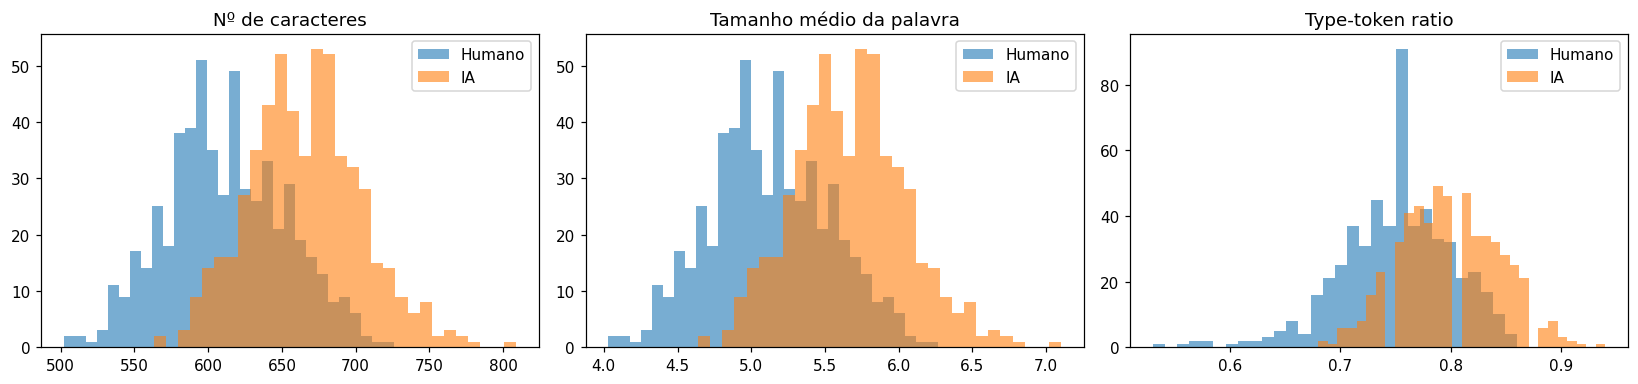

In [ ]:
# 5.2 Distribuições básicas (humano vs IA)
tmp = df.assign(chars=df.text.str.len(),
                avg_wlen=df.text.map(lambda t: np.mean([len(w) for w in t.split()])),
                ttr=df.text.map(lambda t: len(set(t.lower().split())) / len(t.split())))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, ttl in zip(axes, ["chars", "avg_wlen", "ttr"], ["Nº de caracteres", "Tamanho médio da palavra", "Type-token ratio"]):
    for lab, nome in [(0, "Humano"), (1, "IA")]:
        ax.hist(tmp[tmp.label == lab][col], bins=30, alpha=.6, label=nome)
    ax.set_title(ttl); ax.legend()
plt.tight_layout(); savefig("eda_basico"); plt.show()

In [ ]:
# 5.3 Checagem de atalhos (leakage): como os textos começam e que marcas usam
def top_first_words(d, k=8): return d.text.str.split().str[0].str.lower().value_counts(normalize=True).head(k).round(3)
print("Primeiras palavras (humano):\n", top_first_words(df[df.label == 0]).to_dict())
print("Primeiras palavras (IA):\n",     top_first_words(df[df.label == 1]).to_dict())
marks = {"travessão ( - )": " - ", "dois-pontos": ":", "exclamação": "!", "ponto e vírgula": ";", "parênteses": "(", "aspas": '"'}
print("\nFração de textos com cada marca (diferenças muito grandes indicam possível atalho de formatação):")
display(pd.DataFrame({k: df.groupby("label").text.apply(lambda s: s.str.contains(v, regex=False).mean()) for k, v in marks.items()})
        .rename(index={0: "humano", 1: "IA"}).round(3))

Primeiras palavras (humano):
 {'o': 0.127, 'a': 0.112, 'os': 0.025, 'em': 0.022, 'segundo': 0.018, 'as': 0.014, 'the': 0.014, 'com': 0.014}
Primeiras palavras (IA):
 {'o': 0.203, 'a': 0.161, 'em': 0.083, 'no': 0.076, 'na': 0.049, 'uma': 0.02, 'os': 0.016, 'durante': 0.011}

Fração de textos com cada marca (diferenças muito grandes indicam possível atalho de formatação):


,travessão ( - ),dois-pontos,exclamação,ponto e vírgula,parênteses,aspas
label,,,,,,
humano,0.250,0.241,0.038,0.096,0.539,0.288
IA,0.045,0.065,0.002,0.020,0.271,0.152


In [ ]:
# 5.4 Exemplos pareados (mesmo tema)
for dom in DOMAINS:
    g = df[df.domain == dom].group.iloc[0]
    print(f"===== {dom.upper()} · tema: {df[df.group == g].topic.iloc[0][:100]} =====")
    for _, r in df[df.group == g].iterrows(): print(f"[{r.source.upper()}] {r.text}\n")

===== WIKI · tema: Alfonso Capecelatro di Castelpagano =====
[HUMAN] Alfonso Capecelatro (Marselha , 5 de fevereiro de 1824 - 14 de novembro de 1912) foi um arcebispo italiano de Cápua, escritor eclesiástico, bibliotecário do Vaticano e cardeal . Ele era descendente da família dos duques de Castelpagano. Seu pai serviu sob o general Murat, adotou os princípios políticos do período napoleônico e voluntariamente se exilou em Malta e Marselha, quando Fernando de Nápoles, após sua restauração pelo Congresso de Laibach, iniciou a repressão do liberalismo político. A família retornou à Itália em 1826 e a Nápoles em 1830. Aos dezesseis anos, Alfonso entrou no Oratório de São Felipe Neri,

[QWEN] Alfonso Capecelatro di Castelpagano (1398-1472) foi um importante político italiano do século XV. Nascido na cidade de Lucca, Capecelatro se destacou no contexto político da Itália Média e do Renascimento. Ele liderou a corte de Luiz XI de França durante sua primeira viagem à Itália, sendo considerado

---
# Etapa 6 · Divisão treino/validação/teste e métricas

**Objetivo:** avaliar sem vazamento. A divisão é **por tema (grupo)**: o texto humano e o de IA sobre o mesmo assunto ficam sempre no mesmo conjunto (70% treino · 15% validação · 15% teste).

**Métricas:** accuracy, precision, recall, F1 e ROC-AUC, além de:
- **FPR:** fração de humanos classificados como IA (o erro mais grave: acusação injusta);
- **TPR@FPR5%:** IA detectada quando aceitamos errar só 5% dos humanos;
- **IC95% do AUROC** por bootstrap (o teste é pequeno, então reportamos a incerteza).

In [ ]:
# 6.1 Split por grupo
def assign_split(d, seed=SEED, frac=(0.70, 0.15, 0.15)):
    rng = np.random.RandomState(seed)
    groups = np.array(d.group.unique()); rng.shuffle(groups); n = len(groups)
    tr = set(groups[:int(frac[0] * n)]); va = set(groups[int(frac[0] * n):int((frac[0] + frac[1]) * n)])
    d = d.copy(); d["split"] = d.group.map(lambda g: "train" if g in tr else ("val" if g in va else "test")); return d

df = assign_split(df)
display(df.groupby(["split", "label"]).size().unstack().rename(columns={0: "humano", 1: "IA"}))
def get_splits(): return (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))

label,humano,IA
split,,
test,83,83
train,387,387
val,83,83


In [ ]:
# 6.2 Métricas
def evaluate(y, p, thr=0.5):
    y, p = np.asarray(y), np.asarray(p); pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel(); two = len(set(y)) > 1
    fpr_, tpr_, _ = roc_curve(y, p) if two else (np.array([0, 1]), np.array([0, 1]), None)
    return {"acc": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "f1": f1_score(y, pred, zero_division=0),
            "auroc": roc_auc_score(y, p) if two else np.nan, "fpr": fp / (fp + tn) if (fp + tn) else np.nan,
            "tpr@fpr5%": float(np.interp(0.05, fpr_, tpr_))}

def auroc_ci(y, p, n_boot=500, seed=SEED):
    y, p = np.asarray(y), np.asarray(p); r = np.random.RandomState(seed); v = []
    for _ in range(n_boot):
        i = r.randint(0, len(y), len(y))
        if len(set(y[i])) > 1: v.append(roc_auc_score(y[i], p[i]))
    return tuple(np.percentile(v, [2.5, 97.5]))

def balance(d, seed=SEED):
    n = d.label.value_counts().min()
    return pd.concat([d[d.label == l].sample(n, random_state=seed) for l in (0, 1)]).sample(frac=1, random_state=seed).reset_index(drop=True)

---
# Etapa 7 · Abordagem clássica

**Objetivo:** estabelecer a linha de base com técnicas tradicionais de PLN.

| Representação | Modelos |
|---|---|
| **Estilometria** (24 atributos: tamanho de frases/palavras, riqueza vocabular, pontuação, stopwords, conectivos, legibilidade…) | Regressão Logística · Random Forest · **SVM (RBF)** |
| **TF-IDF de palavras** (n-gramas de 1 e 2 palavras) | Regressão Logística · **SVM linear** (probabilidades calibradas) |
| **TF-IDF de caracteres** (n-gramas de 3 a 5 caracteres) | Regressão Logística |

Usamos hiperparâmetros padrão (sem busca extensiva), o que é uma limitação declarada: o foco é comparar famílias de técnicas, não maximizar cada uma.

In [ ]:
# 7.1 Atributos estilométricos para todo o corpus
feats = build_features(tqdm(df.text))
df[FEATURE_COLS] = feats.values
print("Atributos calculados:", feats.shape)

  0%|          | 0/1106 [00:00<?, ?it/s]

Atributos calculados: (1106, 24)


In [ ]:
# 7.2 Arcabouço de detectores (interface única: fit / predict_proba) + registro
class SkDetector:
    # Detector scikit-learn: usa o texto (cols=None) ou colunas numéricas do dataframe
    def __init__(self, name, estimator, cols=None): self.name, self.estimator, self.cols = name, estimator, cols
    def _X(self, d): return d["text"] if self.cols is None else d[self.cols]
    def fit(self, train, val=None): self.model = clone(self.estimator).fit(self._X(train), train["label"]); return self
    def predict_proba(self, d): return self.model.predict_proba(self._X(d))[:, 1]

def LR(): return LogisticRegression(max_iter=3000, class_weight="balanced")
def tfidf_words(): return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50000)
def tfidf_chars(): return TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True, max_features=100000)

DETECTOR_BUILDERS = {
    "Estilométrico + LR":       lambda: SkDetector("Estilométrico + LR",  make_pipeline(StandardScaler(), LR()), FEATURE_COLS),
    "Estilométrico + RF":       lambda: SkDetector("Estilométrico + RF",  RandomForestClassifier(300, class_weight="balanced", random_state=SEED, n_jobs=-1), FEATURE_COLS),
    "Estilométrico + SVM":      lambda: SkDetector("Estilométrico + SVM", make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=SEED)), FEATURE_COLS),
    "TF-IDF palavras + LR":     lambda: SkDetector("TF-IDF palavras + LR",  make_pipeline(tfidf_words(), LR())),
    "TF-IDF palavras + SVM":    lambda: SkDetector("TF-IDF palavras + SVM", make_pipeline(tfidf_words(), CalibratedClassifierCV(LinearSVC(class_weight="balanced"), cv=3))),
    "TF-IDF caracteres + LR":   lambda: SkDetector("TF-IDF caracteres + LR", make_pipeline(tfidf_chars(), LR())),
}
CLASSICAL = list(DETECTOR_BUILDERS)
ID_DETECTORS, ID_PROBS, ID_VAL_AUC = {}, {}, {}

def fit_eval_id(names):
    # Treina em train, escolhe/monitora em val e avalia em test (mesma distribuição)
    train, val, test = get_splits(); rows = []
    for n in names:
        det = DETECTOR_BUILDERS[n]().fit(train, val)
        p = det.predict_proba(test); ID_DETECTORS[n], ID_PROBS[n] = det, p
        ID_VAL_AUC[n] = roc_auc_score(val.label, det.predict_proba(val))
        rows.append({"detector": n, **evaluate(test.label, p), "AUROC val": ID_VAL_AUC[n]})
    return pd.DataFrame(rows).set_index("detector").round(3)

In [ ]:
# 7.3 Resultados da abordagem clássica (teste)
tab_classico = fit_eval_id(CLASSICAL)
display(tab_classico)
best_c = tab_classico["auroc"].idxmax()
fam = {"estilometria": [n for n in CLASSICAL if n.startswith("Estilom")],
       "TF-IDF de palavras": [n for n in CLASSICAL if n.startswith("TF-IDF palavras")],
       "TF-IDF de caracteres": [n for n in CLASSICAL if n.startswith("TF-IDF caracteres")]}
melhor_fam = {f: tab_classico.loc[ns, "auroc"].max() for f, ns in fam.items()}
display(Markdown(f"**Resumo:** entre os métodos clássicos, o melhor foi **{best_c}** (AUROC = {tab_classico.loc[best_c,'auroc']:.3f}, "
                 f"FPR = {tab_classico.loc[best_c,'fpr']:.1%}). Melhor AUROC por família: "
                 + ", ".join(f"{f} = {v:.3f}" for f, v in melhor_fam.items())
                 + f". A família com mais sinal foi **{max(melhor_fam, key=melhor_fam.get)}**."))

,acc,precision,recall,f1,auroc,fpr,tpr@fpr5%,AUROC val
detector,,,,,,,,
Estilométrico + LR,0.880,0.862,0.904,0.882,0.947,0.145,0.663,0.946
Estilométrico + RF,0.892,0.882,0.904,0.893,0.952,0.120,0.711,0.923
Estilométrico + SVM,0.880,0.862,0.904,0.882,0.957,0.145,0.771,0.939
TF-IDF palavras + LR,0.934,0.939,0.928,0.933,0.981,0.060,0.928,0.981
TF-IDF palavras + SVM,0.934,0.929,0.940,0.934,0.986,0.072,0.928,0.987
TF-IDF caracteres + LR,0.934,0.929,0.940,0.934,0.985,0.072,0.928,0.967


**Resumo:** entre os métodos clássicos, o melhor foi **TF-IDF palavras + SVM** (AUROC = 0.986, FPR = 7.2%). Melhor AUROC por família: estilometria = 0.957, TF-IDF de palavras = 0.986, TF-IDF de caracteres = 0.985. A família com mais sinal foi **TF-IDF de palavras**.

---
# Etapa 8 · Mineração de dados: padrões de escrita

**Objetivo:** responder à **PQ2**: existem padrões de escrita associados às duas classes? Vamos além de "o modelo acerta" e perguntamos **o que** diferencia humano e IA, **com que força** e **se isso vale nos dois domínios**.

Para cada atributo calculamos: medianas por classe, teste de Mann-Whitney (com correção de Bonferroni) e o **delta de Cliff** (tamanho de efeito: |δ| < 0,15 desprezível · < 0,33 pequeno · < 0,47 médio · ≥ 0,47 grande). A coluna `consistente` indica se o sinal é o mesmo na Wikipedia e nas notícias.

In [ ]:
# 8.1 Tabela de efeitos
def magnitude(d):
    d = abs(d); return "desprezível" if d < .147 else "pequeno" if d < .33 else "médio" if d < .474 else "grande"

def cliff(a, h):
    u, p = mannwhitneyu(a, h, alternative="two-sided"); return 2 * u / (len(a) * len(h)) - 1, p

rows = []
for c in FEATURE_COLS:
    a, h = df.loc[df.label == 1, c].values, df.loc[df.label == 0, c].values
    dl, p = cliff(a, h)
    r = {"atributo": FEATURE_LABELS[c], "mediana humano": np.median(h), "mediana IA": np.median(a), "δ Cliff": dl, "magnitude": magnitude(dl), "p": p}
    for dom in DOMAINS:
        r[f"δ {dom}"] = cliff(df.loc[(df.label == 1) & (df.domain == dom), c].values, df.loc[(df.label == 0) & (df.domain == dom), c].values)[0]
    rows.append(r)
efeitos = pd.DataFrame(rows)
efeitos["p (Bonferroni)"] = np.minimum(efeitos.p * len(efeitos), 1)
efeitos["consistente"] = np.sign(efeitos[f"δ {DOMAINS[0]}"]) == np.sign(efeitos[f"δ {DOMAINS[1]}"])
efeitos = efeitos.reindex(efeitos["δ Cliff"].abs().sort_values(ascending=False).index).drop(columns="p").reset_index(drop=True)
display(efeitos.round(3)); efeitos.to_csv(os.path.join(PROJ, "data", "tabela_efeitos.csv"), index=False)

top = efeitos.iloc[0]
display(Markdown(f"**Resumo:** o atributo mais discriminativo é **{top['atributo']}** (δ = {top['δ Cliff']:.2f}, efeito {top['magnitude']}; "
                 f"textos de IA têm {'valores maiores' if top['δ Cliff'] > 0 else 'valores menores'}). "
                 f"{int((efeitos['p (Bonferroni)'] < .05).sum())} de {len(efeitos)} atributos diferem de forma significativa; "
                 f"{int(efeitos['consistente'].sum())} mantêm o mesmo sentido nos dois domínios."))

,atributo,mediana humano,mediana IA,δ Cliff,magnitude,δ wiki,δ noticias,p (Bonferroni),consistente
0,Sílabas por palavra (aprox.),2.120,2.390,0.728,grande,0.730,0.727,0.000,True
1,Legibilidade (Flesch-PT; maior = mais fácil),48.337,23.431,-0.717,grande,-0.727,-0.710,0.000,True
2,Tamanho médio da palavra (letras),4.886,5.495,0.705,grande,0.671,0.736,0.000,True
3,Proporção de palavras longas (>=9 letras),0.134,0.206,0.624,grande,0.610,0.641,0.000,True
4,Proporção de maiúsculas,0.034,0.018,-0.586,grande,-0.714,-0.502,0.000,True
5,Riqueza vocabular (type-token ratio),0.731,0.782,0.560,grande,0.670,0.490,0.000,True
6,Palavras que aparecem uma só vez,0.590,0.663,0.553,grande,0.655,0.493,0.000,True
7,Proporção de dígitos,0.010,0.000,-0.463,médio,-0.592,-0.412,0.000,True
8,Repetição de bigramas,0.030,0.010,-0.411,médio,-0.584,-0.306,0.000,True
9,Variação relativa do tamanho das frases,0.454,0.333,-0.402,médio,-0.510,-0.317,0.000,True


**Resumo:** o atributo mais discriminativo é **Sílabas por palavra (aprox.)** (δ = 0.73, efeito grande; textos de IA têm valores maiores). 22 de 24 atributos diferem de forma significativa; 22 mantêm o mesmo sentido nos dois domínios.

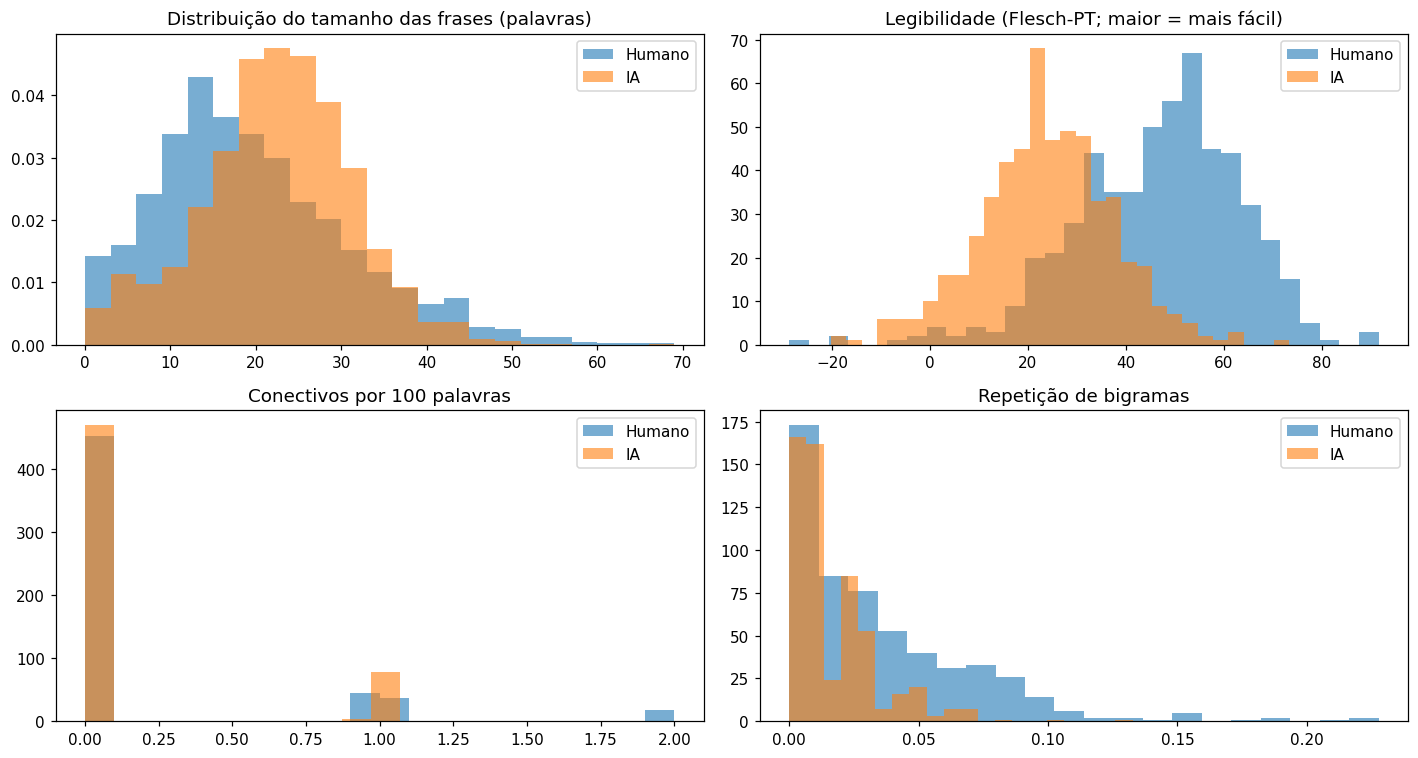

,humano,IA,diferença (IA−humano)
além disso,0.020,0.087,0.067
assim,0.043,0.018,-0.025
porém,0.022,0.004,-0.018
ou seja,0.013,0.000,-0.013
logo,0.018,0.007,-0.011
no entanto,0.034,0.024,-0.011
portanto,0.011,0.000,-0.011
entretanto,0.007,0.000,-0.007
contudo,0.005,0.000,-0.005
por isso,0.005,0.000,-0.005


In [ ]:
# 8.2 Visualizações dos padrões: tamanho das frases, conectivos, legibilidade, repetição
sent_len = {lab: [len(s.split()) for t in df[df.label == lab].text for s in split_sentences(t)] for lab in (0, 1)}
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for lab, nome in [(0, "Humano"), (1, "IA")]:
    ax[0, 0].hist(sent_len[lab], bins=range(0, 70, 3), alpha=.6, density=True, label=nome)
    ax[0, 1].hist(df[df.label == lab].st_flesch, bins=30, alpha=.6, label=nome)
    ax[1, 0].hist(df[df.label == lab].st_connectives, bins=20, alpha=.6, label=nome)
    ax[1, 1].hist(df[df.label == lab].st_rep_bigram, bins=20, alpha=.6, label=nome)
for a, t in zip(ax.ravel(), ["Distribuição do tamanho das frases (palavras)", "Legibilidade (Flesch-PT; maior = mais fácil)",
                             "Conectivos por 100 palavras", "Repetição de bigramas"]):
    a.set_title(t); a.legend()
plt.tight_layout(); savefig("padroes_escrita"); plt.show()

# Conectivos mais usados por classe (por 100 palavras)
conn = {lab: Counter() for lab in (0, 1)}
for lab in (0, 1):
    for t in df[df.label == lab].text:
        low = t.lower()
        for c_ in CONNECTIVES: conn[lab][c_] += len(re.findall(r"\b" + re.escape(c_) + r"\b", low))
tot = {lab: (df.label == lab).sum() * TRUNC_WORDS / 100 for lab in (0, 1)}
tab_conn = pd.DataFrame({"humano": {k: v / tot[0] for k, v in conn[0].items()}, "IA": {k: v / tot[1] for k, v in conn[1].items()}})
tab_conn["diferença (IA−humano)"] = tab_conn["IA"] - tab_conn["humano"]
display(tab_conn.reindex(tab_conn["diferença (IA−humano)"].abs().sort_values(ascending=False).index).head(10).round(3))

### 8.3 Quais atributos o modelo mais usa?
Comparamos a **importância** no Random Forest e os **coeficientes** da regressão logística (atributos padronizados). Atributos com efeito forte na tabela 8.1 *e* importância alta no modelo são os mais confiáveis para a discussão.

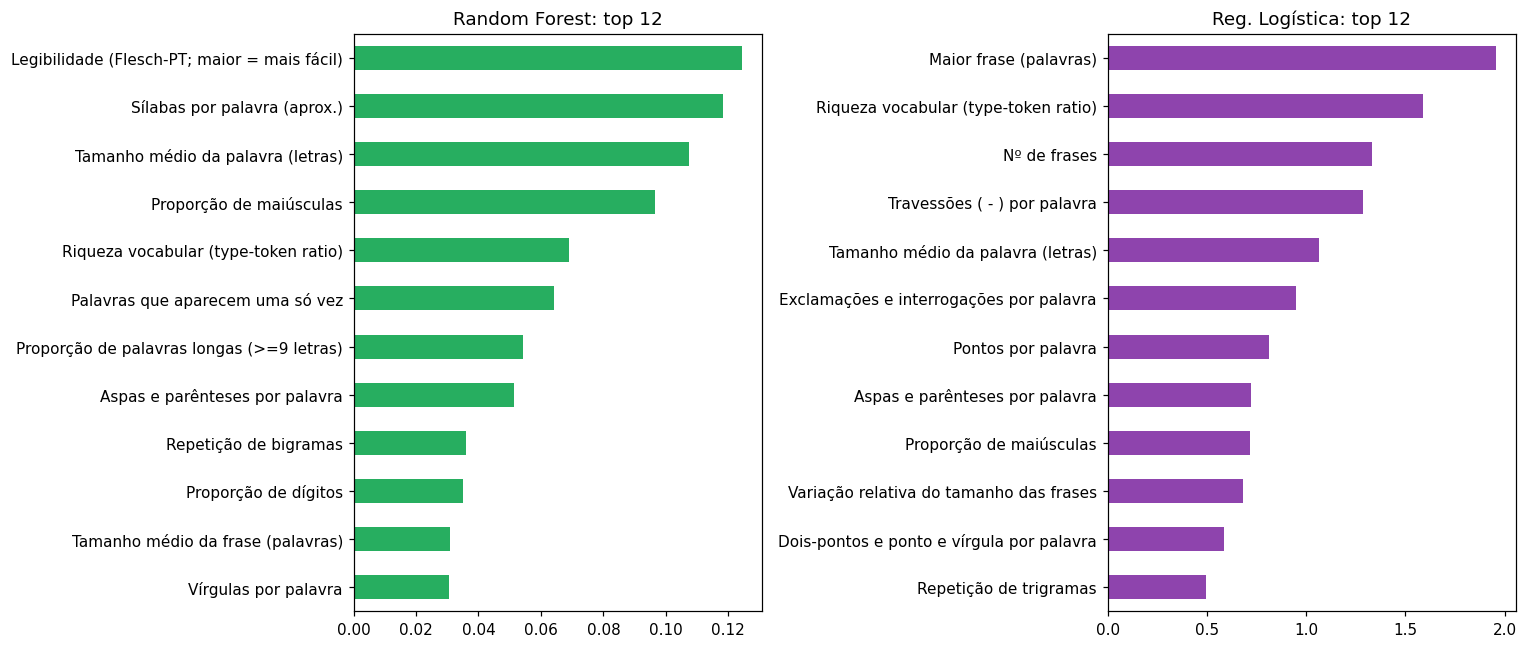

In [ ]:
# 8.3 Importância dos atributos
rf = ID_DETECTORS["Estilométrico + RF"].model
lr = ID_DETECTORS["Estilométrico + LR"].model.steps[-1][1]
imp = pd.DataFrame({"RF (importância)": rf.feature_importances_, "LR (|coef| padronizado)": np.abs(lr.coef_[0])},
                   index=[FEATURE_LABELS[c] for c in FEATURE_COLS])
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
imp["RF (importância)"].sort_values().tail(12).plot.barh(ax=ax[0], color="#27ae60", title="Random Forest: top 12")
imp["LR (|coef| padronizado)"].sort_values().tail(12).plot.barh(ax=ax[1], color="#8e44ad", title="Reg. Logística: top 12")
plt.tight_layout(); savefig("importancia_atributos"); plt.show()

### 8.4 Clustering (não supervisionado)
Sem usar os rótulos, os documentos formam grupos? E esses grupos correspondem à **autoria** (humano/IA) ou a outra coisa (**domínio**, **gerador**)? Medimos com ARI e NMI (0 = nenhuma relação, 1 = idêntico).

In [ ]:
# 8.4 K-Means nos atributos estilométricos
Xs = StandardScaler().fit_transform(df[FEATURE_COLS])
res_k = []
for k in (2, 4):
    cl = KMeans(k, n_init=10, random_state=SEED).fit_predict(Xs)
    for nome, ref in [("autoria (humano/IA)", df.label), ("domínio", df.domain), ("fonte (humano/qwen/phi)", df.source)]:
        res_k.append({"k": k, "comparado com": nome, "ARI": adjusted_rand_score(ref, cl), "NMI": normalized_mutual_info_score(ref, cl)})
res_k = pd.DataFrame(res_k); display(res_k.round(3))
cl2 = KMeans(2, n_init=10, random_state=SEED).fit_predict(Xs)
display(pd.crosstab(cl2, df.label.map({0: "humano", 1: "IA"}), rownames=["cluster"]))
best_ref = res_k[res_k.k == 2].set_index("comparado com").ARI.idxmax()
display(Markdown(f"**Resumo:** com k = 2, os clusters se alinham mais a **{best_ref}** "
                 f"(ARI = {res_k[(res_k.k==2)].set_index('comparado com').ARI.max():.2f}). "
                 f"{'Isso sugere que, sem supervisão, a diferença de domínio pesa mais que a de autoria.' if best_ref != 'autoria (humano/IA)' else 'Há estrutura de autoria detectável sem supervisão.'}"))

,k,comparado com,ARI,NMI
0,2,autoria (humano/IA),0.497,0.411
1,2,domínio,0.001,0.001
2,2,fonte (humano/qwen/phi),0.331,0.333
3,4,autoria (humano/IA),0.379,0.329
4,4,domínio,0.010,0.023
5,4,fonte (humano/qwen/phi),0.208,0.281


label,IA,humano
cluster,,
0,47,437
1,506,116


**Resumo:** com k = 2, os clusters se alinham mais a **autoria (humano/IA)** (ARI = 0.50). Há estrutura de autoria detectável sem supervisão.

### 8.5 Visualização do espaço de atributos (PCA e t-SNE)

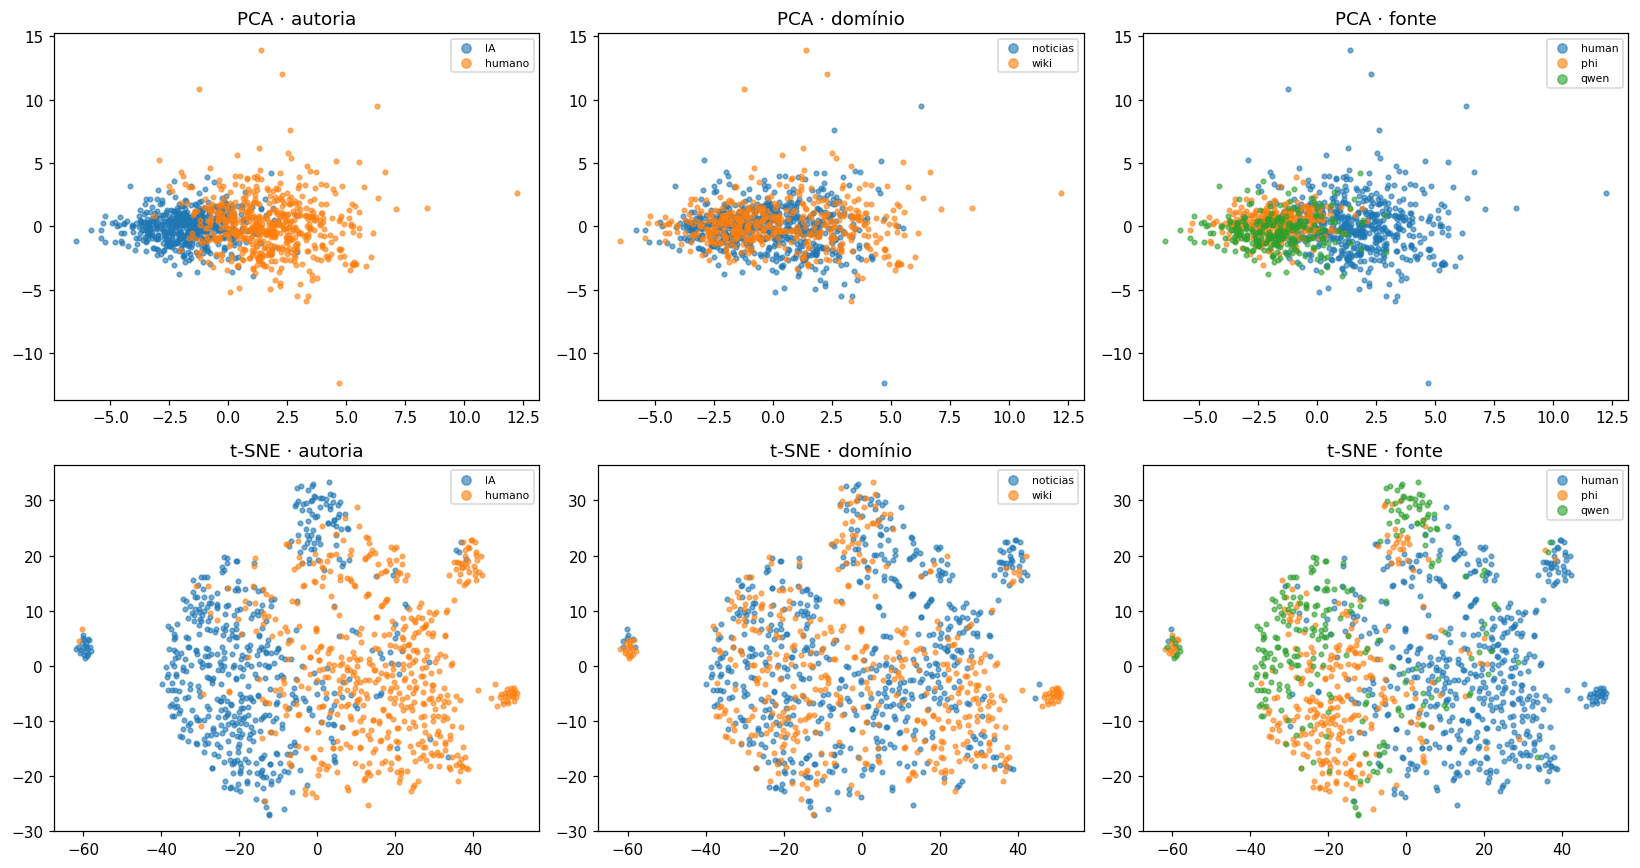

In [ ]:
# 8.5 PCA e t-SNE dos atributos estilométricos
Zp = PCA(2, random_state=SEED).fit_transform(Xs)
Zt = TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(Xs)

def scatter_by(ax, Z, cats, title):
    for c in sorted(pd.unique(cats)):
        m = np.asarray(cats) == c; ax.scatter(Z[m, 0], Z[m, 1], s=9, alpha=.6, label=str(c))
    ax.set_title(title); ax.legend(fontsize=7, markerscale=2)

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for row, (Z, nome) in enumerate([(Zp, "PCA"), (Zt, "t-SNE")]):
    scatter_by(ax[row, 0], Z, df.label.map({0: "humano", 1: "IA"}).values, f"{nome} · autoria")
    scatter_by(ax[row, 1], Z, df.domain.values, f"{nome} · domínio")
    scatter_by(ax[row, 2], Z, df.source.values, f"{nome} · fonte")
plt.tight_layout(); savefig("pca_tsne_estilometria"); plt.show()

---
# Etapa 9 · Deep learning: fine-tuning do BERTimbau

**Objetivo:** treinar um classificador binário baseado em **BERTimbau** (BERT pré-treinado em português) e comparar com a linha de base clássica.

- Laço de treino em PyTorch com precisão mista; 3 épocas; guarda o **melhor estado segundo o AUROC de validação** (o teste não participa da escolha).
- Registramos a curva de treino e depois visualizamos as **representações internas** do modelo antes e depois do fine-tuning.

In [ ]:
# 9.1 Detector BERTimbau
class BertDetector:
    name = "BERTimbau (fine-tuning)"
    def __init__(self, epochs=3, lr=3e-5, bs=16, max_len=BERT_MAX_LEN): self.epochs, self.lr, self.bs, self.max_len, self.history = epochs, lr, bs, max_len, []

    def fit(self, train, val=None):
        set_seed(SEED); self.history = []
        self.tok = AutoTokenizer.from_pretrained(BERT_MODEL)
        self.model = AutoModelForSequenceClassification.from_pretrained(BERT_MODEL, num_labels=2).to(DEVICE)
        enc = self.tok(list(train.text), truncation=True, max_length=self.max_len, padding=True, return_tensors="pt")
        dl = DataLoader(TensorDataset(enc["input_ids"], enc["attention_mask"], torch.tensor(train.label.values)), batch_size=self.bs, shuffle=True)
        opt = torch.optim.AdamW(self.model.parameters(), lr=self.lr, weight_decay=0.01)
        total = len(dl) * self.epochs; sch = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
        amp = DEVICE == "cuda"; scaler = torch.amp.GradScaler("cuda", enabled=amp); best, state = -1, None
        for ep in range(self.epochs):
            self.model.train(); tot = 0
            for ids, att, y in dl:
                ids, att, y = ids.to(DEVICE), att.to(DEVICE), y.to(DEVICE); opt.zero_grad()
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp):
                    loss = self.model(input_ids=ids, attention_mask=att, labels=y).loss
                scaler.scale(loss).backward(); scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sch.step(); tot += loss.item()
            h = {"época": ep + 1, "loss treino": tot / len(dl)}
            if val is not None and val.label.nunique() > 1:
                h["AUROC val"] = roc_auc_score(val.label, self.predict_proba(val))
                if h["AUROC val"] > best: best = h["AUROC val"]; state = {k: v.detach().cpu().clone() for k, v in self.model.state_dict().items()}
            self.history.append(h); print("  ", {k: round(v, 4) for k, v in h.items()})
        if state is not None: self.model.load_state_dict(state)
        return self

    def _batches(self, texts, bs):
        for i in range(0, len(texts), bs):
            yield self.tok(texts[i:i + bs], truncation=True, max_length=self.max_len, padding=True, return_tensors="pt").to(DEVICE)

    @torch.no_grad()
    def predict_proba(self, d, bs=64):
        self.model.eval(); out = []
        for enc in self._batches(list(d["text"]), bs):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                lg = self.model(**enc).logits
            out += torch.softmax(lg.float(), -1)[:, 1].cpu().tolist()
        return np.array(out)

    @torch.no_grad()
    def embed(self, texts, bs=64):   # representação interna (média dos tokens da última camada)
        self.model.eval(); out = []
        for enc in self._batches(list(texts), bs):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                h = self.model.bert(**enc).last_hidden_state
            m = enc["attention_mask"].unsqueeze(-1).float(); out.append(((h.float() * m).sum(1) / m.sum(1)).cpu().numpy())
        return np.vstack(out)

    def free(self): del self.model; gc.collect(); torch.cuda.empty_cache()

BERT_NAME = "BERTimbau (fine-tuning)"
DETECTOR_BUILDERS[BERT_NAME] = lambda: BertDetector()
tab_bert = fit_eval_id([BERT_NAME]); display(tab_bert)

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

   {'época': 1, 'loss treino': 0.4489, 'AUROC val': np.float64(0.9697)}
   {'época': 2, 'loss treino': 0.0882, 'AUROC val': np.float64(0.9965)}
   {'época': 3, 'loss treino': 0.0226, 'AUROC val': np.float64(0.9964)}


,acc,precision,recall,f1,auroc,fpr,tpr@fpr5%,AUROC val
detector,,,,,,,,
BERTimbau (fine-tuning),0.976,0.976,0.976,0.976,0.999,0.024,1.0,0.997


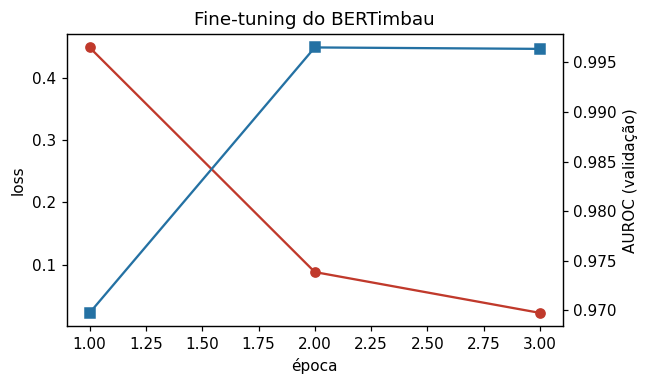

In [ ]:
# 9.2 Curva de treino
hist = pd.DataFrame(ID_DETECTORS[BERT_NAME].history).set_index("época")
fig, ax = plt.subplots(figsize=(6, 3.6)); hist["loss treino"].plot(ax=ax, marker="o", color="#c0392b", label="loss de treino")
ax2 = ax.twinx(); hist["AUROC val"].plot(ax=ax2, marker="s", color="#2471a3", label="AUROC val"); ax.set_ylabel("loss"); ax2.set_ylabel("AUROC (validação)")
ax.set_title("Fine-tuning do BERTimbau"); plt.tight_layout(); savefig("bert_curva_treino"); plt.show()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


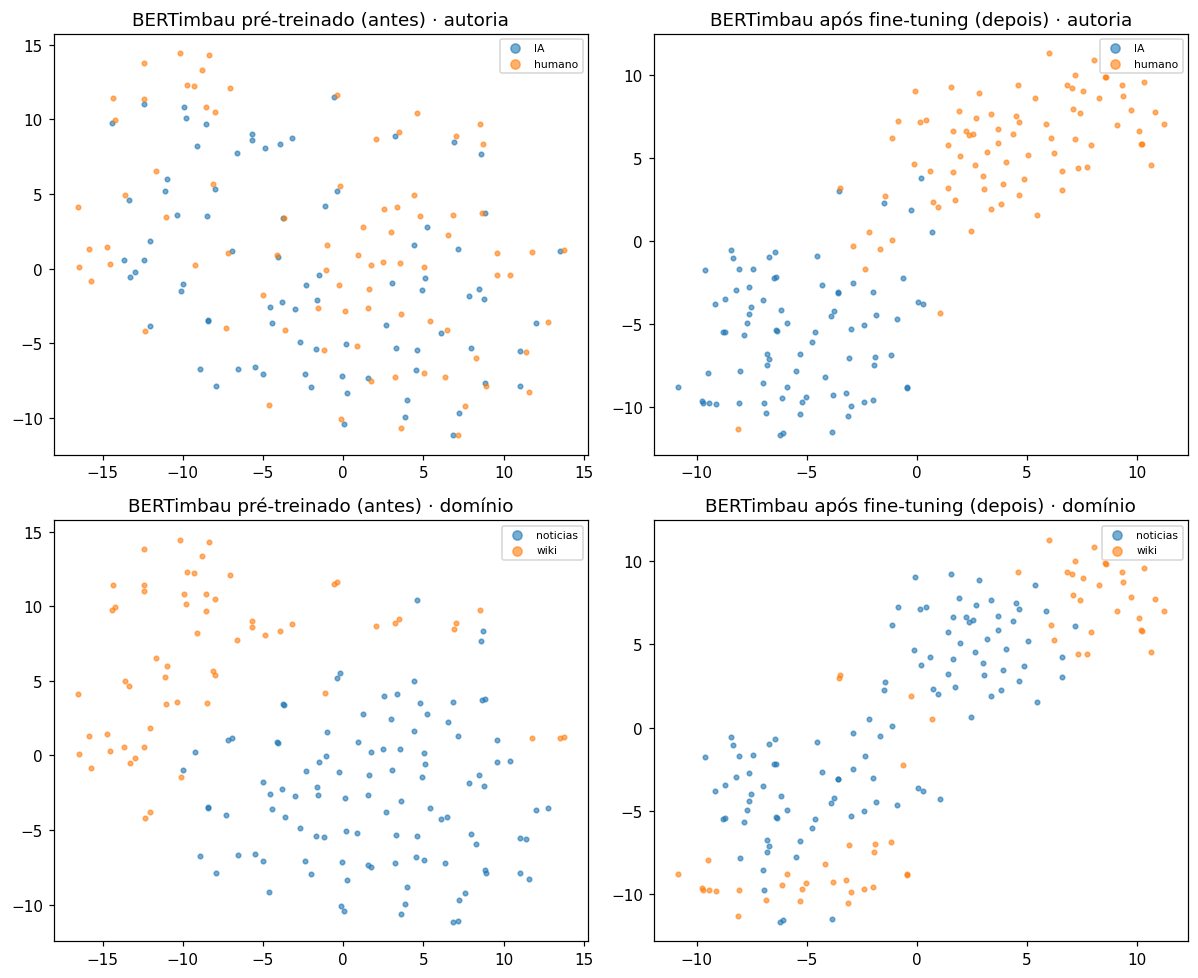

In [ ]:
# 9.3 Representações internas: BERTimbau ANTES vs. DEPOIS do fine-tuning (conjunto de teste)
_, _, test_df = get_splits()
base_tok = AutoTokenizer.from_pretrained(BERT_MODEL); base_model = AutoModel.from_pretrained(BERT_MODEL).to(DEVICE).eval()

@torch.no_grad()
def embed_base(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        enc = base_tok(texts[i:i + bs], truncation=True, max_length=BERT_MAX_LEN, padding=True, return_tensors="pt").to(DEVICE)
        h = base_model(**enc).last_hidden_state; m = enc["attention_mask"].unsqueeze(-1).float()
        out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    return np.vstack(out)

E_before = embed_base(list(test_df.text)); E_after = ID_DETECTORS[BERT_NAME].embed(test_df.text)
del base_model; gc.collect(); torch.cuda.empty_cache()
perp = max(5, min(30, len(test_df) // 4))
fig, ax = plt.subplots(2, 2, figsize=(11, 9))
for j, (E, nome) in enumerate([(E_before, "BERTimbau pré-treinado (antes)"), (E_after, "BERTimbau após fine-tuning (depois)")]):
    Z = TSNE(2, perplexity=perp, init="pca", random_state=SEED).fit_transform(E)
    scatter_by(ax[0, j], Z, test_df.label.map({0: "humano", 1: "IA"}).values, nome + " · autoria")
    scatter_by(ax[1, j], Z, test_df.domain.values, nome + " · domínio")
plt.tight_layout(); savefig("tsne_bertimbau"); plt.show()

---
# Etapa 10 · Comparação dos modelos (mesma distribuição)

**Objetivo:** responder à **PQ1** com todos os modelos lado a lado no conjunto de teste, com incerteza.

,acc,precision,recall,f1,AUROC,IC95% inf,IC95% sup,FPR,TPR@FPR5%
detector,,,,,,,,,
BERTimbau (fine-tuning),0.976,0.976,0.976,0.976,0.999,0.996,1.000,0.024,1.000
TF-IDF palavras + SVM,0.934,0.929,0.940,0.934,0.986,0.971,0.996,0.072,0.928
TF-IDF caracteres + LR,0.934,0.929,0.940,0.934,0.985,0.970,0.995,0.072,0.928
TF-IDF palavras + LR,0.934,0.939,0.928,0.933,0.981,0.960,0.995,0.060,0.928
Estilométrico + SVM,0.880,0.862,0.904,0.882,0.957,0.925,0.979,0.145,0.771
Estilométrico + RF,0.892,0.882,0.904,0.893,0.952,0.914,0.978,0.120,0.711
Estilométrico + LR,0.880,0.862,0.904,0.882,0.947,0.912,0.977,0.145,0.663


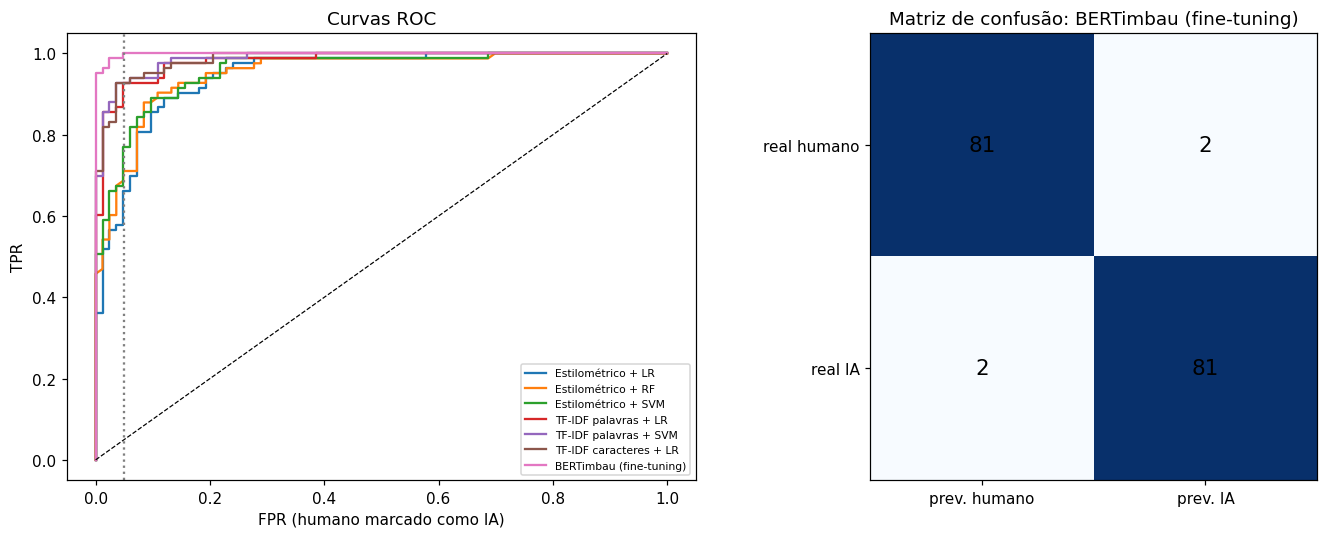

**Resumo (PQ1):** o melhor modelo na mesma distribuição é **BERTimbau (fine-tuning)** (AUROC = 0.999, IC95% [0.996, 1.000], FPR = 2.4%). Os intervalos de confiança do primeiro e do segundo colocados se sobrepõem: não dá para afirmar que o melhor seja estatisticamente superior. Este é o cenário mais favorável: a Etapa 11 testa o que acontece quando as condições mudam.

In [ ]:
# 10.1 Tabela comparativa
_, _, test_df = get_splits(); rows = []
for n, p in ID_PROBS.items():
    m = evaluate(test_df.label, p); lo, hi = auroc_ci(test_df.label, p)
    rows.append({"detector": n, "acc": m["acc"], "precision": m["precision"], "recall": m["recall"], "f1": m["f1"],
                 "AUROC": m["auroc"], "IC95% inf": lo, "IC95% sup": hi, "FPR": m["fpr"], "TPR@FPR5%": m["tpr@fpr5%"]})
tab_id = pd.DataFrame(rows).set_index("detector").sort_values("AUROC", ascending=False)
display(tab_id.round(3)); tab_id.round(4).to_csv(os.path.join(PROJ, "data", "resultados_mesma_distribuicao.csv"))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n, p in ID_PROBS.items():
    f, t, _ = roc_curve(test_df.label, p); ax[0].plot(f, t, label=n)
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].axvline(.05, color="gray", ls=":")
ax[0].set(xlabel="FPR (humano marcado como IA)", ylabel="TPR", title="Curvas ROC"); ax[0].legend(fontsize=7)
best_n = tab_id.index[0]; cm = confusion_matrix(test_df.label, ID_PROBS[best_n] >= .5)
ax[1].imshow(cm, cmap="Blues"); ax[1].set_xticks([0, 1], ["prev. humano", "prev. IA"]); ax[1].set_yticks([0, 1], ["real humano", "real IA"])
for i in range(2):
    for j in range(2): ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
ax[1].set_title(f"Matriz de confusão: {best_n}"); plt.tight_layout(); savefig("comparacao_roc_confusao"); plt.show()

b = tab_id.iloc[0]
sobrepoe = len(tab_id) > 1 and tab_id["IC95% sup"].iloc[1] >= b["IC95% inf"]
display(Markdown(f"**Resumo (PQ1):** o melhor modelo na mesma distribuição é **{best_n}** (AUROC = {b['AUROC']:.3f}, "
                 f"IC95% [{b['IC95% inf']:.3f}, {b['IC95% sup']:.3f}], FPR = {b['FPR']:.1%}). "
                 f"{'Os intervalos de confiança do primeiro e do segundo colocados se sobrepõem: não dá para afirmar que o melhor seja estatisticamente superior.' if sobrepoe else 'O melhor modelo se destaca do segundo colocado.'} "
                 f"Este é o cenário mais favorável: a Etapa 11 testa o que acontece quando as condições mudam."))

---
# Etapa 11 · Generalização: quando as condições mudam

**Objetivo:** responder à **PQ3**, a parte mais importante do trabalho. Um detector que acerta "em casa" pode falhar fora dela.

| Experimento | Treino | Teste |
|---|---|---|
| **11.1 Entre geradores** | humanos + textos do **Qwen** | humanos + textos do **Phi** (nunca visto) |
| | humanos + textos do **Phi** | humanos + textos do **Qwen** |
| **11.2 Entre domínios** | Wikipedia | notícias (e vice-versa) |
| **11.3 Testes de estresse** | (modelos já treinados) | texto curto (50 e 30 palavras) e texto com ruído/erros |
| **11.4 Gerador externo** | (modelos já treinados com Qwen + Phi) | humanos do teste + textos do **Gemini** sobre os mesmos temas |

Nos experimentos 11.1 e 11.2 todos os detectores são retreinados (os de BERTimbau levam ~2–4 min cada).

In [ ]:
# 11.1 Infraestrutura + experimentos entre geradores
RESULTS = [{"experimento": "0. Mesma distribuição", "detector": n, **evaluate(test_df.label, p)} for n, p in ID_PROBS.items()]

def run_experiment(exp, train, val, test, names=None):
    names = names or list(DETECTOR_BUILDERS); train, val, test = balance(train), balance(val), balance(test)
    print(f"\n### {exp} | treino={len(train)} val={len(val)} teste={len(test)}")
    for n in names:
        print(" ->", n); det = DETECTOR_BUILDERS[n]().fit(train, val)
        RESULTS.append({"experimento": exp, "detector": n, **evaluate(test.label, det.predict_proba(test))})
        if hasattr(det, "free"): det.free()
    pd.DataFrame(RESULTS).to_csv(os.path.join(PROJ, "data", "resultados_robustez_parcial.csv"), index=False)   # checkpoint

train, val, test = get_splits()
def only(d, gen): return d[(d.label == 0) | (d.source == gen)]
run_experiment("1a. treina Qwen → testa Phi", only(train, "qwen"), only(val, "qwen"), only(test, "phi"))
run_experiment("1b. treina Phi → testa Qwen", only(train, "phi"),  only(val, "phi"),  only(test, "qwen"))


### 1a. treina Qwen → testa Phi | treino=340 val=96 teste=86
 -> Estilométrico + LR
 -> Estilométrico + RF
 -> Estilométrico + SVM
 -> TF-IDF palavras + LR
 -> TF-IDF palavras + SVM
 -> TF-IDF caracteres + LR
 -> BERTimbau (fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

   {'época': 1, 'loss treino': 0.6093, 'AUROC val': np.float64(0.9761)}
   {'época': 2, 'loss treino': 0.3594, 'AUROC val': np.float64(0.9922)}
   {'época': 3, 'loss treino': 0.1594, 'AUROC val': np.float64(0.9926)}

### 1b. treina Phi → testa Qwen | treino=434 val=70 teste=80
 -> Estilométrico + LR
 -> Estilométrico + RF
 -> Estilométrico + SVM
 -> TF-IDF palavras + LR
 -> TF-IDF palavras + SVM
 -> TF-IDF caracteres + LR
 -> BERTimbau (fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

   {'época': 1, 'loss treino': 0.515, 'AUROC val': np.float64(0.9869)}
   {'época': 2, 'loss treino': 0.1056, 'AUROC val': np.float64(0.9976)}
   {'época': 3, 'loss treino': 0.0338, 'AUROC val': np.float64(0.9976)}


In [ ]:
# 11.2 Entre domínios (testa em TODOS os textos do domínio não visto)
train, val, test = get_splits()
run_experiment("2a. treina wiki → testa notícias", train[train.domain == "wiki"], val[val.domain == "wiki"], df[df.domain == "noticias"])
run_experiment("2b. treina notícias → testa wiki", train[train.domain == "noticias"], val[val.domain == "noticias"], df[df.domain == "wiki"])


### 2a. treina wiki → testa notícias | treino=342 val=70 teste=634
 -> Estilométrico + LR
 -> Estilométrico + RF
 -> Estilométrico + SVM
 -> TF-IDF palavras + LR
 -> TF-IDF palavras + SVM
 -> TF-IDF caracteres + LR
 -> BERTimbau (fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

   {'época': 1, 'loss treino': 0.5358, 'AUROC val': np.float64(0.9812)}
   {'época': 2, 'loss treino': 0.2013, 'AUROC val': np.float64(0.9976)}
   {'época': 3, 'loss treino': 0.0701, 'AUROC val': np.float64(0.9984)}

### 2b. treina notícias → testa wiki | treino=432 val=96 teste=472
 -> Estilométrico + LR
 -> Estilométrico + RF
 -> Estilométrico + SVM
 -> TF-IDF palavras + LR
 -> TF-IDF palavras + SVM
 -> TF-IDF caracteres + LR
 -> BERTimbau (fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

   {'época': 1, 'loss treino': 0.5848, 'AUROC val': np.float64(0.9809)}
   {'época': 2, 'loss treino': 0.1783, 'AUROC val': np.float64(0.9948)}
   {'época': 3, 'loss treino': 0.0424, 'AUROC val': np.float64(0.9952)}


In [ ]:
# 11.3 Testes de estresse: texto curto e texto com ruído (usa os modelos já treinados, sem retreinar)
rng = np.random.RandomState(SEED)
def remove_accents(w): return "".join(c for c in unicodedata.normalize("NFD", w) if unicodedata.category(c) != "Mn")
def attack_noise(t, p_swap=0.08, p_acc=0.30):
    out = []
    for w in t.split():
        if rng.rand() < p_acc: w = remove_accents(w)
        if len(w) > 3 and rng.rand() < p_swap:
            i = rng.randint(1, len(w) - 2); w = w[:i] + w[i + 1] + w[i] + w[i + 2:]
        out.append(w)
    return " ".join(out)

_, _, test_df = get_splits()
STRESS = {"curto (50 palavras)": (lambda t: first_n_words(t, 50), True), "curto (30 palavras)": (lambda t: first_n_words(t, 30), True),
          "ruído/erros (só IA)": (attack_noise, False)}
rows_s = []
for nome, (fn, to_humans) in STRESS.items():
    d = test_df.copy(); mask = np.ones(len(d), bool) if to_humans else (d.label.values == 1)
    d.loc[mask, "text"] = [fn(t) for t in d.loc[mask, "text"]]
    d[FEATURE_COLS] = build_features(d.text).values
    for n, det in ID_DETECTORS.items():
        p = det.predict_proba(d); rows_s.append({"experimento": f"3. {nome}", "detector": n, **evaluate(d.label, p)})
RESULTS += rows_s

### 11.4 Gerador externo: Gemini (modelo comercial grande, nunca visto no treino)
Os geradores do treino são modelos abertos pequenos (1,5B e 3,8B de parâmetros). A pergunta prática é: **o detector reconhece texto de um modelo comercial que as pessoas realmente usam?** Para cada tema do conjunto de **teste**, pedimos ao Gemini um texto com o **mesmo prompt** dos outros geradores; o texto passa pela **mesma limpeza**; e comparamos com os textos humanos desses temas. Nenhum modelo é retreinado.

Requer a chave `GEMINI_API_KEY` nos *Secrets* do Colab. O plano gratuito tem limite de requisições por minuto, por isso há pausas entre as chamadas (~10–15 min no total). Os textos ficam em cache no Drive.

In [ ]:
# 11.4 Gerador externo (Gemini)
EXT_PATH = os.path.join(PROJ, "data", f"geracao_gemini_n{N_PER_DOMAIN}.csv")
_, _, test_df = get_splits()
ext_topics = test_df[test_df.label == 0][["group", "domain", "topic"]].drop_duplicates("group").reset_index(drop=True)

def get_gemini_key():
    try:
        from google.colab import userdata
        return userdata.get("GEMINI_API_KEY")
    except Exception:
        return os.environ.get("GEMINI_API_KEY")

def run_gemini(topics, path=EXT_PATH, pause=4.5, retries=4, max_fail_streak=5):
    done = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=["group", "raw_text"])
    todo = topics[~topics.group.isin(done.group)]
    if len(todo) == 0: return done
    key = get_gemini_key()
    if not key:
        print("GEMINI_API_KEY não encontrada nos Secrets do Colab: experimento 11.4 pulado."); return done if len(done) else None
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=key)
    base_cfg = dict(system_instruction=SYSTEM_PROMPT, temperature=0.8, top_p=0.95, max_output_tokens=800)
    try:    cfg = types.GenerateContentConfig(**base_cfg, thinking_config=types.ThinkingConfig(thinking_budget=0))
    except Exception: cfg = types.GenerateContentConfig(**base_cfg)
    rows, streak = done.to_dict("records"), 0
    for _, r in tqdm(todo.iterrows(), total=len(todo), desc="Gemini"):
        prompt = PROMPT_TEMPLATES[r.domain].format(topic=str(r.topic).replace('"', "'"))
        ok = False
        for a in range(retries):
            try:
                resp = client.models.generate_content(model=GEMINI_MODEL, contents=prompt, config=cfg)
                rows.append({"group": r.group, "raw_text": resp.text or ""}); ok = True; break
            except Exception as e:
                msg = str(e)
                if "thinking" in msg.lower():                       # modelo sem suporte a thinking_budget
                    cfg = types.GenerateContentConfig(**base_cfg); continue
                wait = pause * 2 ** (a + 1); print(f"  erro ({type(e).__name__}): {msg[:120]} | nova tentativa em {wait:.0f}s"); time.sleep(wait)
        streak = 0 if ok else streak + 1
        if streak >= max_fail_streak:
            print("Muitas falhas seguidas (chave, nome do modelo ou limite de uso). Parando a geração."); break
        if len(rows) % 10 == 0: pd.DataFrame(rows).to_csv(path, index=False)
        time.sleep(pause)
    out = pd.DataFrame(rows); out.to_csv(path, index=False); return out

EXT_OK, d_ext = False, None
gem = run_gemini(ext_topics) if RUN_EXTERNAL else None
if gem is not None and len(gem):
    g = gem.merge(ext_topics, on="group", how="inner").assign(source="gemini", label=1)
    g["text"] = g.raw_text.fillna("").astype(str).map(strip_llm_preamble).map(preprocess)   # mesma limpeza da Etapa 4
    g = apply_filters(g)
    print("Descartes do Gemini:", g.drop_reason.value_counts().to_dict() or "nenhum")
    g = g[g.drop_reason.isna()].copy(); g["text"] = g.text.map(lambda t: first_n_words(t, TRUNC_WORDS))
    hum = test_df[(test_df.label == 0) & test_df.group.isin(g.group)]
    cols = ["group", "domain", "topic", "source", "label", "text"]
    d_ext = pd.concat([hum[cols], g[cols]], ignore_index=True)
    if d_ext.label.value_counts().min() >= 10:
        d_ext[FEATURE_COLS] = build_features(d_ext.text).values
        for n, det in ID_DETECTORS.items():
            RESULTS.append({"experimento": "4. gerador externo (Gemini)", "detector": n, **evaluate(d_ext.label, det.predict_proba(d_ext))})
        EXT_OK = True
        print(f"Teste externo: {len(hum)} humanos × {len(g)} textos do Gemini")
        ex = g.iloc[0]; print(f"\nExemplo Gemini [{ex.domain}] · tema: {ex.topic[:80]}\n{ex.text}")
    else:
        print("Poucos textos válidos do Gemini: experimento 11.4 não incluído nos resultados.")

GEMINI_API_KEY não encontrada nos Secrets do Colab: experimento 11.4 pulado.


experimento,0. Mesma distribuição,1a. treina Qwen → testa Phi,1b. treina Phi → testa Qwen,2a. treina wiki → testa notícias,2b. treina notícias → testa wiki,3. curto (30 palavras),3. curto (50 palavras),3. ruído/erros (só IA)
detector,,,,,,,,
BERTimbau (fine-tuning),0.999,0.995,0.986,0.938,0.978,0.889,0.971,0.982
TF-IDF palavras + SVM,0.986,0.943,0.929,0.928,0.977,0.815,0.917,0.982
TF-IDF caracteres + LR,0.985,0.985,0.944,0.929,0.980,0.871,0.930,0.980
TF-IDF palavras + LR,0.981,0.942,0.921,0.923,0.979,0.811,0.907,0.977
Estilométrico + SVM,0.957,0.923,0.901,0.926,0.958,0.782,0.868,0.962
Estilométrico + RF,0.952,0.924,0.910,0.918,0.943,0.748,0.846,0.954
Estilométrico + LR,0.947,0.902,0.909,0.938,0.973,0.776,0.840,0.951


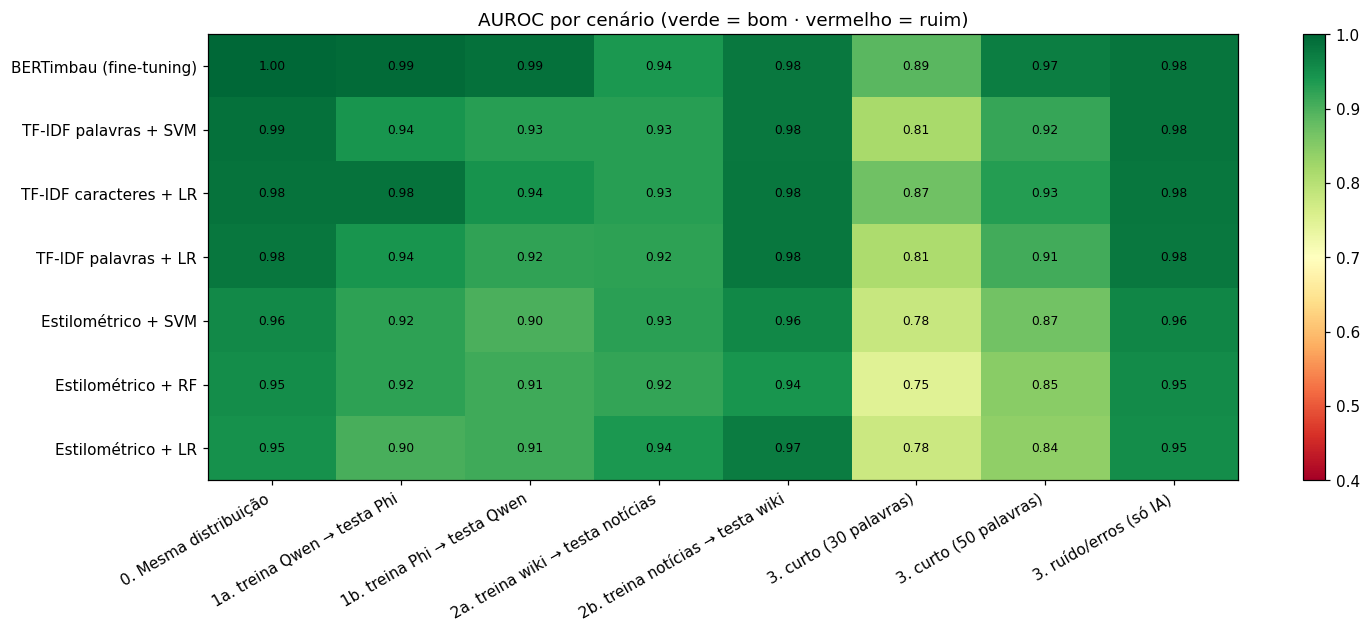

F1 por cenário (limiar 0,5):


experimento,0. Mesma distribuição,1a. treina Qwen → testa Phi,1b. treina Phi → testa Qwen,2a. treina wiki → testa notícias,2b. treina notícias → testa wiki,3. curto (30 palavras),3. curto (50 palavras),3. ruído/erros (só IA)
detector,,,,,,,,
BERTimbau (fine-tuning),0.976,0.944,0.963,0.837,0.861,0.731,0.914,0.903
TF-IDF palavras + SVM,0.934,0.854,0.746,0.821,0.906,0.639,0.845,0.928
TF-IDF caracteres + LR,0.934,0.966,0.853,0.855,0.928,0.450,0.789,0.928
TF-IDF palavras + LR,0.933,0.867,0.776,0.839,0.910,0.624,0.818,0.914
Estilométrico + SVM,0.882,0.795,0.767,0.849,0.904,0.710,0.802,0.895
Estilométrico + RF,0.893,0.795,0.743,0.843,0.870,0.697,0.789,0.893
Estilométrico + LR,0.882,0.734,0.805,0.861,0.908,0.687,0.730,0.882


FPR (humanos marcados como IA, limiar 0,5):


experimento,0. Mesma distribuição,1a. treina Qwen → testa Phi,1b. treina Phi → testa Qwen,2a. treina wiki → testa notícias,2b. treina notícias → testa wiki,3. curto (30 palavras),3. curto (50 palavras),3. ruído/erros (só IA)
detector,,,,,,,,
BERTimbau (fine-tuning),0.024,0.093,0.050,0.274,0.318,0.024,0.060,0.024
TF-IDF palavras + SVM,0.072,0.093,0.050,0.050,0.186,0.181,0.120,0.072
TF-IDF caracteres + LR,0.072,0.070,0.075,0.120,0.110,0.036,0.072,0.072
TF-IDF palavras + LR,0.060,0.093,0.025,0.104,0.182,0.169,0.133,0.060
Estilométrico + SVM,0.145,0.093,0.125,0.202,0.064,0.205,0.313,0.145
Estilométrico + RF,0.120,0.093,0.100,0.208,0.102,0.398,0.277,0.120
Estilométrico + LR,0.145,0.163,0.150,0.218,0.085,0.843,0.699,0.145


**Resumo (PQ3):**

- **Entre geradores:** queda média de AUROC de **-0.036**; o mais robusto foi **BERTimbau (fine-tuning)** (-0.009) e o menos robusto **TF-IDF palavras + SVM** (-0.050).
- **Entre domínios:** queda média de **-0.023**.
- **Estresse (texto curto/ruído):** queda média de **-0.079**.
- Pior cenário no geral: **3. curto (30 palavras)** (queda média -0.159).

Quedas grandes **não são fracasso**: indicam que o detector aprendeu características do gerador/domínio de treino. Esse é um resultado central do trabalho.

In [ ]:
# 11.5 Resultados: tabela, mapa de calor e queda de desempenho
res = pd.DataFrame(RESULTS); res.to_csv(os.path.join(PROJ, "data", "resultados_robustez.csv"), index=False)
piv = res.pivot(index="detector", columns="experimento", values="auroc").round(3)
piv = piv.loc[tab_id.index]
display(piv)

def heatmap(p, title, vmin=0.4, vmax=1.0):
    fig, ax = plt.subplots(figsize=(1.35 * len(p.columns) + 3, 0.55 * len(p) + 2))
    im = ax.imshow(p.values, cmap="RdYlGn", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(p.columns)), p.columns, rotation=30, ha="right"); ax.set_yticks(range(len(p)), p.index)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]): ax.text(j, i, f"{p.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    plt.colorbar(im); ax.set_title(title); plt.tight_layout()
heatmap(piv, "AUROC por cenário (verde = bom · vermelho = ruim)"); savefig("heatmap_auroc"); plt.show()

print("F1 por cenário (limiar 0,5):"); display(res.pivot(index="detector", columns="experimento", values="f1").loc[tab_id.index].round(3))
print("FPR (humanos marcados como IA, limiar 0,5):"); display(res.pivot(index="detector", columns="experimento", values="fpr").loc[tab_id.index].round(3))

# Resumo automático
base_col = "0. Mesma distribuição"
queda = piv.sub(piv[base_col], axis=0).drop(columns=base_col)
gen_cols = [c for c in piv.columns if c.startswith("1")]; dom_cols = [c for c in piv.columns if c.startswith("2")]
str_cols = [c for c in piv.columns if c.startswith("3")]; ext_cols = [c for c in piv.columns if c.startswith("4")]
rob_gen = queda[gen_cols].mean(axis=1).sort_values(ascending=False)
linhas = [f"- **Entre geradores:** queda média de AUROC de **{queda[gen_cols].mean().mean():+.3f}**; o mais robusto foi **{rob_gen.index[0]}** ({rob_gen.iloc[0]:+.3f}) "
          f"e o menos robusto **{rob_gen.index[-1]}** ({rob_gen.iloc[-1]:+.3f}).",
          f"- **Entre domínios:** queda média de **{queda[dom_cols].mean().mean():+.3f}**.",
          f"- **Estresse (texto curto/ruído):** queda média de **{queda[str_cols].mean().mean():+.3f}**."]
if ext_cols:
    e = piv[ext_cols[0]].sort_values(ascending=False)
    linhas.append(f"- **Gerador externo (Gemini):** AUROC médio de **{e.mean():.3f}** (queda {queda[ext_cols[0]].mean():+.3f}); "
                  f"melhor detector neste cenário: **{e.index[0]}** ({e.iloc[0]:.3f}).")
linhas.append(f"- Pior cenário no geral: **{queda.mean().idxmin()}** (queda média {queda.mean().min():+.3f}).")
display(Markdown("**Resumo (PQ3):**\n\n" + "\n".join(linhas) + "\n\n"
                 "Quedas grandes **não são fracasso**: indicam que o detector aprendeu características do gerador/domínio de treino. "
                 "Esse é um resultado central do trabalho."))

---
# Etapa 12 · Análise de erros e interpretabilidade

**Objetivo:** entender **onde** o melhor modelo erra e **por quê**. Os falsos positivos (humano marcado como IA) merecem atenção especial.

In [ ]:
# 12.1 Erros do BERTimbau no teste
_, _, test_df = get_splits(); p = ID_PROBS[BERT_NAME]; t = test_df.assign(p=p)
print("FPR por domínio (humano marcado como IA):"); display(t[t.label == 0].groupby("domain").p.apply(lambda s: (s >= .5).mean()).round(3).to_frame("FPR"))
print("Recall por gerador e domínio (IA detectada):"); display(t[t.label == 1].groupby(["source", "domain"]).p.apply(lambda s: (s >= .5).mean()).unstack().round(3))
print("\n===== Humanos com MAIOR p(IA): falsos positivos =====")
for _, r in t[t.label == 0].sort_values("p", ascending=False).head(3).iterrows(): print(f"[{r.domain}] p(IA)={r.p:.3f}\n{r.text}\n")
print("===== IA com MENOR p(IA): falsos negativos =====")
for _, r in t[t.label == 1].sort_values("p").head(3).iterrows(): print(f"[{r.source}/{r.domain}] p(IA)={r.p:.3f}\n{r.text}\n")

FPR por domínio (humano marcado como IA):


,FPR
domain,
noticias,0.038
wiki,0.000


Recall por gerador e domínio (IA detectada):


domain,noticias,wiki
source,,
phi,1.000,0.938
qwen,0.962,1.000



===== Humanos com MAIOR p(IA): falsos positivos =====
[noticias] p(IA)=0.916
Para comemorar o Natal, os Correios, anualmente, emitem selos postais registrando a festa cristã que marca o nascimento de Jesus e ressaltando importantes ícones natalinos, que encantam pela simbologia e beleza. Na decoração natalina são utilizados vários símbolos, cada um com seu significado, dos quais podemos citar a árvore, as velas, as luzes, os enfeites, o sino, os anjinhos, as guirlandas, a ceia, as bolas, as meias e os presentes. Mas esta magnífica festa só começa mesmo com o tocar dos sinos em todo o mundo. O sino sempre anunciava as grandes festas populares, e, no Natal, com seu toque

[noticias] p(IA)=0.725
Uma das táticas mais comuns era utilizar pombos-correios, para ajudar os soldados durante os confrontos. As aves tinham o objetivo de enviar mensagens aos homens que estavam no campo de batalha. Adestrados, rápidos e muito inteligentes, esses animais foram responsáveis por salvar a vida de muitas

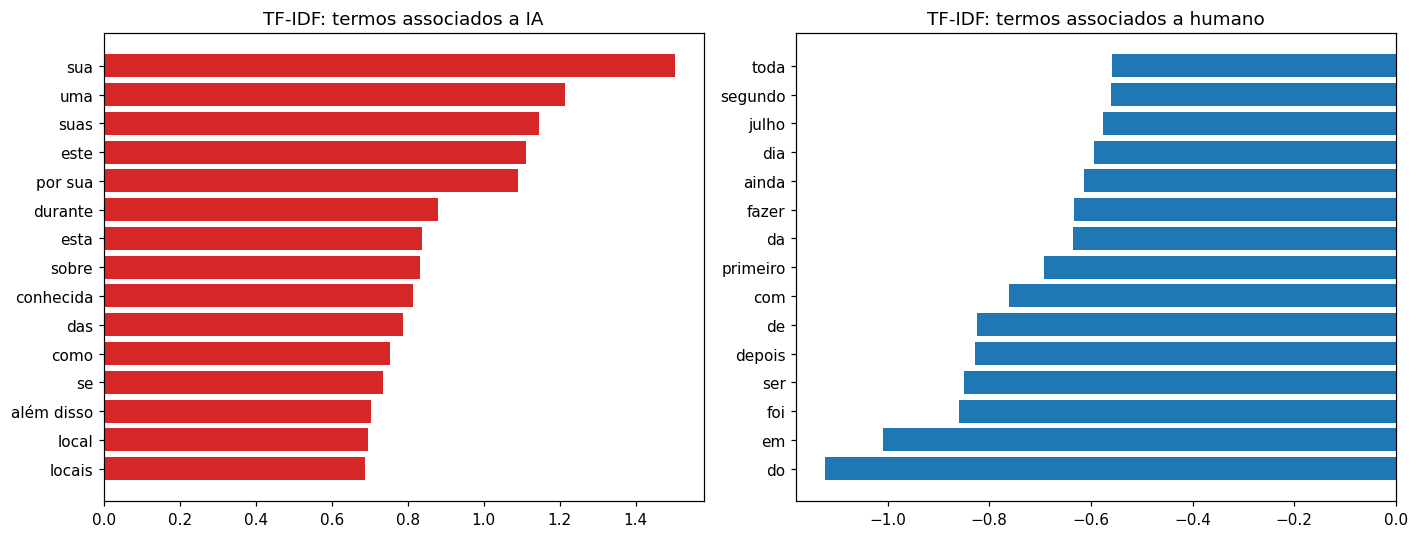

**Resumo:** verifique se os termos mais fortes são **estilo** (conectivos, fórmulas de ênfase) ou **conteúdo/domínio** (nomes próprios, termos típicos da Wikipedia ou de notícias). Termos de conteúdo explicam a queda de desempenho entre domínios na Etapa 11.

In [ ]:
# 12.2 O que o TF-IDF + LR aprendeu (palavras mais associadas a cada classe)
steps = ID_DETECTORS["TF-IDF palavras + LR"].model.steps; vec, clf = steps[0][1], steps[-1][1]
names = np.array(vec.get_feature_names_out()); coef = clf.coef_[0]; ia_i, h_i = np.argsort(coef)[-15:], np.argsort(coef)[:15]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].barh(names[ia_i], coef[ia_i], color="tab:red"); ax[0].set_title("TF-IDF: termos associados a IA")
ax[1].barh(names[h_i], coef[h_i], color="tab:blue"); ax[1].set_title("TF-IDF: termos associados a humano")
plt.tight_layout(); savefig("tfidf_termos"); plt.show()
display(Markdown("**Resumo:** verifique se os termos mais fortes são **estilo** (conectivos, fórmulas de ênfase) ou **conteúdo/domínio** "
                 "(nomes próprios, termos típicos da Wikipedia ou de notícias). Termos de conteúdo explicam a queda de desempenho entre domínios na Etapa 11."))

---
# Etapa 13 · Plataforma de análise de autoria (Projeto Integrador)

**Objetivo:** levar o que foi treinado aqui ao usuário final. A plataforma (`app.py`, em **Gradio**) recebe um texto e mostra:

| Requisito (8.5) | Como aparece no app |
|---|---|
| Classificação humano/IA | Veredito em três faixas: provavelmente humano · inconclusivo · provavelmente IA |
| Probabilidade estimada | P(IA) combinada (média dos dois modelos) |
| Indicadores estilométricos | Tabela com o valor do texto e as médias de humanos e de IA do treino |
| Resultado do modelo clássico | Linha própria na tabela de resultados por modelo |
| Resultado do Transformer | Linha própria (BERTimbau) |
| Visualizações | Gráfico de posição do texto entre a média humana e a média de IA nos 10 indicadores mais discriminativos |
| Aviso de estimativa experimental | Fixo no topo da página e repetido junto ao resultado |

Textos longos são divididos em trechos de 100 palavras (tamanho do treino) e as probabilidades são a média dos trechos; textos curtos recebem aviso de baixa confiabilidade; se os dois modelos discordarem fortemente, o app avisa.

In [ ]:
%%writefile app.py
"""
app.py - Plataforma de análise de autoria textual (humano vs. IA)

Projeto: Humano ou IA? Identificação de autoria textual em português (FATEC Jundiaí)
Autores: Allan Vytor Francisco Oliveira, Gabriel Passos, Guilherme Cavalcante Tenório

Execução:  python app.py   ->   http://127.0.0.1:7860
Requer, na mesma pasta: stylometry.py e a pasta models/ exportada pelo notebook.
"""
import json
import os

import gradio as gr
import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from stylometry import FEATURE_COLS, FEATURE_LABELS, TRUNC_WORDS, build_features, n_words, preprocess, windows

BASE = os.path.dirname(os.path.abspath(__file__))
MODELS = os.path.join(BASE, "models")

META = json.load(open(os.path.join(MODELS, "meta.json"), encoding="utf-8"))
REF = json.load(open(os.path.join(MODELS, "reference_stats.json"), encoding="utf-8"))
CLS = joblib.load(os.path.join(MODELS, "classico.joblib"))
TOK = AutoTokenizer.from_pretrained(os.path.join(MODELS, "bertimbau"))
BERT = AutoModelForSequenceClassification.from_pretrained(os.path.join(MODELS, "bertimbau")).eval()
MAX_LEN = META.get("bert_max_len", 192)
T_HUMAN, T_AI = META["thresholds"]["human_max"], META["thresholds"]["ai_min"]
MIN_WORDS_WARN = 50

AVISO = ("**Estimativa experimental, não prova de autoria.** Os modelos foram treinados com trechos de cerca de "
         f"{TRUNC_WORDS} palavras em português (Wikipedia e notícias) e com textos de dois modelos de linguagem abertos. "
         "O resultado é uma probabilidade estatística que pode errar, inclusive marcando como IA um texto escrito por "
         "uma pessoa. Não use este resultado para acusar ou punir ninguém.")


def prob_classico(chunks):
    if CLS["kind"] == "text":
        p = CLS["model"].predict_proba(chunks)[:, 1]
    else:
        p = CLS["model"].predict_proba(build_features(chunks)[CLS["cols"]])[:, 1]
    return float(np.mean(p))


@torch.no_grad()
def prob_bert(chunks):
    enc = TOK(chunks, truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
    p = torch.softmax(BERT(**enc).logits, -1)[:, 1].numpy()
    return float(np.mean(p))


def veredito(p):
    if p >= T_AI:
        return "Provavelmente gerado por IA"
    if p <= T_HUMAN:
        return "Provavelmente escrito por humano"
    return "Inconclusivo"


def indicadores(chunks):
    f = build_features(chunks).mean()            # média dos trechos de ~100 palavras
    rows = []
    for c in FEATURE_COLS:
        r, v = REF[c], float(f[c])
        d_h = abs(v - r["human_mean"]) / (r["human_std"] + 1e-9)
        d_a = abs(v - r["ai_mean"]) / (r["ai_std"] + 1e-9)
        rows.append({"Indicador": FEATURE_LABELS[c], "Este texto": v, "Média humanos": r["human_mean"],
                     "Média IA": r["ai_mean"], "Mais próximo de": "IA" if d_a < d_h else "Humano", "effect": r["effect"]})
    return pd.DataFrame(rows)


def grafico(tab, k=10):
    top = tab.reindex(tab["effect"].abs().sort_values(ascending=False).index).head(k)
    pos = [(r["Este texto"] - r["Média humanos"]) / (r["Média IA"] - r["Média humanos"])
           if abs(r["Média IA"] - r["Média humanos"]) > 1e-9 else 0.5 for _, r in top.iterrows()]
    pos = np.clip(pos, -1, 2)
    y = np.arange(len(top))[::-1]
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    ax.axvspan(-1.05, 0.5, color="#2471a3", alpha=0.06)
    ax.axvspan(0.5, 2.05, color="#c0392b", alpha=0.06)
    ax.axvline(0, color="#2471a3", ls="--", lw=1.2, label="média dos humanos")
    ax.axvline(1, color="#c0392b", ls="--", lw=1.2, label="média da IA")
    ax.scatter(pos, y, s=70, color="#222", zorder=3, label="este texto")
    ax.set_yticks(y, top["Indicador"], fontsize=8)
    ax.set_xlim(-1.05, 2.05)
    ax.set_xlabel("Posição relativa (0 = média humana · 1 = média da IA)")
    ax.set_title("Os 10 indicadores que mais separam humano e IA")
    ax.legend(fontsize=7, loc="lower right")
    plt.tight_layout()
    return fig


def analisar(texto):
    t = preprocess(texto or "")
    nw = n_words(t)
    if nw < 10:
        return "Cole um texto em português com pelo menos algumas frases.", None, None, None, None
    chunks = windows(t, TRUNC_WORDS, min_last=50)
    pc, pb = prob_classico(chunks), prob_bert(chunks)
    pm = (pc + pb) / 2

    avisos = []
    if nw < MIN_WORDS_WARN:
        avisos.append(f"Texto curto ({nw} palavras): a confiabilidade é baixa. O ideal é ter {TRUNC_WORDS} palavras ou mais.")
    if len(chunks) > 1:
        avisos.append(f"Texto dividido em {len(chunks)} trechos de ~{TRUNC_WORDS} palavras; as probabilidades são a média dos trechos.")
    if abs(pc - pb) > 0.4:
        avisos.append("Os dois modelos discordam fortemente: trate o resultado como inconclusivo.")

    resumo = (f"## {veredito(pm)}\n**Probabilidade estimada de IA (média dos dois modelos): {pm:.0%}**\n\n"
              + "".join(f"- {a}\n" for a in avisos) + "\n" + AVISO)
    modelos = pd.DataFrame([
        {"Modelo": f"Clássico: {CLS['name']}", "P(IA)": f"{pc:.1%}", "Classificação": veredito(pc)},
        {"Modelo": "Transformer: BERTimbau (fine-tuning)", "P(IA)": f"{pb:.1%}", "Classificação": veredito(pb)},
    ])
    tab = indicadores(chunks)
    fig = grafico(tab)
    tab_show = tab.drop(columns="effect").round(3)
    return resumo, {"IA": pm, "Humano": 1 - pm}, modelos, tab_show, fig


def rodape():
    linhas = []
    for nome, m in META.get("test_metrics", {}).items():
        linhas.append(f"{nome}: AUROC {m['auroc']:.3f} · F1 {m['f1']:.3f} · FPR {m['fpr']:.1%}")
    return ("**Desempenho no conjunto de teste (mesma distribuição do treino):** " + " | ".join(linhas)
            + f"  \nModelos treinados em {META.get('criado_em', '?')}. Fora dessas condições (outros geradores, "
              "outros gêneros, textos editados por humanos) o desempenho tende a cair; veja a Etapa 11 do notebook.")


with gr.Blocks(title="Humano ou IA? · Análise de autoria") as demo:
    gr.Markdown("# Humano ou IA? Análise de autoria textual\n"
                "Projeto Integrador · FATEC Jundiaí · Allan Vytor Francisco Oliveira, Gabriel Passos e "
                "Guilherme Cavalcante Tenório\n\n" + AVISO)
    with gr.Row():
        with gr.Column(scale=3):
            entrada = gr.Textbox(lines=12, label="Texto em português", placeholder="Cole aqui o texto (ideal: 100 palavras ou mais)")
            botao = gr.Button("Analisar", variant="primary")
        with gr.Column(scale=2):
            out_resumo = gr.Markdown()
            out_prob = gr.Label(num_top_classes=2, label="Probabilidade estimada")
    out_modelos = gr.Dataframe(label="Resultado por modelo", interactive=False)
    with gr.Row():
        out_graf = gr.Plot(label="Visualização dos indicadores")
        out_tab = gr.Dataframe(label="Indicadores estilométricos", interactive=False)
    gr.Markdown(rodape())
    botao.click(analisar, inputs=entrada, outputs=[out_resumo, out_prob, out_modelos, out_tab, out_graf])

if __name__ == "__main__":
    demo.launch(server_name="127.0.0.1", server_port=7860)

Writing app.py


### 13.2 Exportação dos artefatos
Exportamos para `export/` (e para um `.zip` baixável):
- `models/classico.joblib`: o melhor modelo clássico (escolhido pelo AUROC de **validação**, não de teste);
- `models/bertimbau/`: o BERTimbau com fine-tuning (pesos + tokenizer);
- `models/reference_stats.json`: médias/desvios dos atributos por classe (para os gráficos do app);
- `models/meta.json`: versões de bibliotecas, limiares e métricas;
- `stylometry.py` (o **mesmo** módulo do treino), `app.py`, `requirements.txt` (com as versões do treino) e `README.md`.

In [ ]:
# 13.2 Exportação
EXPORT = os.path.join(PROJ, "export"); MODELS_DIR = os.path.join(EXPORT, "models")
shutil.rmtree(EXPORT, ignore_errors=True); os.makedirs(os.path.join(MODELS_DIR, "bertimbau"))
_, _, test_df = get_splits()

best_classico = max(CLASSICAL, key=lambda n: ID_VAL_AUC[n]); det = ID_DETECTORS[best_classico]
joblib.dump({"name": best_classico, "kind": "text" if det.cols is None else "features", "cols": det.cols, "model": det.model},
            os.path.join(MODELS_DIR, "classico.joblib"))
bert = ID_DETECTORS[BERT_NAME]; bert.model.save_pretrained(os.path.join(MODELS_DIR, "bertimbau")); bert.tok.save_pretrained(os.path.join(MODELS_DIR, "bertimbau"))

tr = df[df.split == "train"]; ref = {}
for c in FEATURE_COLS:
    h, a = tr.loc[tr.label == 0, c], tr.loc[tr.label == 1, c]; sd = np.sqrt((h.var() + a.var()) / 2) + 1e-9
    ref[c] = {"human_mean": float(h.mean()), "human_std": float(h.std()), "ai_mean": float(a.mean()), "ai_std": float(a.std()), "effect": float((a.mean() - h.mean()) / sd)}
json.dump(ref, open(os.path.join(MODELS_DIR, "reference_stats.json"), "w"), ensure_ascii=False, indent=1)

meta = {"criado_em": datetime.now().isoformat(timespec="seconds"), "trunc_words": TRUNC_WORDS, "bert_model": BERT_MODEL, "bert_max_len": BERT_MAX_LEN,
        "thresholds": {"human_max": 0.35, "ai_min": 0.65}, "classico": best_classico,
        "versions": {"scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__, "torch": torch.__version__,
                     "transformers": transformers.__version__, "joblib": joblib.__version__},
        "test_metrics": {best_classico: evaluate(test_df.label, ID_PROBS[best_classico]), BERT_NAME: evaluate(test_df.label, ID_PROBS[BERT_NAME])},
        "dataset": {"n_textos": int(len(df)), "dominios": sorted(df.domain.unique().tolist()), "geradores": GENERATORS}}
json.dump(meta, open(os.path.join(MODELS_DIR, "meta.json"), "w"), ensure_ascii=False, indent=1, default=float)

np_major = int(np.__version__.split(".")[0])
open(os.path.join(EXPORT, "requirements.txt"), "w").write("\n".join([
    "gradio>=4.44", "torch", f"transformers=={transformers.__version__}", f"scikit-learn=={sklearn.__version__}",
    f"numpy>={np_major}.0,<{np_major + 1}", "pandas", "scipy", "matplotlib", f"joblib>={joblib.__version__}"]) + "\n")
open(os.path.join(EXPORT, "README.md"), "w", encoding="utf-8").write(
    "# Plataforma: Humano ou IA? (análise de autoria textual)\n\n"
    "Autores: Allan Vytor Francisco Oliveira, Gabriel Passos, Guilherme Cavalcante Tenório (FATEC Jundiaí)\n\n"
    "```bash\npython -m venv .venv\nsource .venv/bin/activate   # Windows: .venv\\Scripts\\activate\n"
    "pip install -r requirements.txt\npython app.py   # abre em http://127.0.0.1:7860\n```\n\n"
    "O resultado é uma estimativa experimental, não prova de autoria.\n")

for f in ["stylometry.py", "app.py"]: shutil.copy(f, os.path.join(EXPORT, f))
shutil.copy(CLEAN_PATH, os.path.join(EXPORT, "dataset_limpo.csv"))
zip_path = shutil.make_archive(os.path.join(PROJ, "artefatos_plataforma"), "zip", EXPORT)
print("Modelo clássico exportado:", best_classico, "| scikit-learn:", sklearn.__version__)
print("Pacote:", zip_path, f"({os.path.getsize(zip_path)/1e6:.0f} MB)")
try:
    from google.colab import files; files.download(zip_path)       # baixa para o seu computador
except Exception as e:
    print("Baixe o .zip pelo painel de arquivos ou pelo Google Drive.", e)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo clássico exportado: TF-IDF palavras + SVM | scikit-learn: 1.6.1
Pacote: /content/drive/MyDrive/autoria_humano_vs_ia/artefatos_plataforma.zip (405 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 13.3 (Opcional) Demonstração da plataforma dentro do próprio Colab, com link público temporário
RUN_DEMO = False
if RUN_DEMO:
    !pip -q install gradio
    os.chdir(EXPORT); sys.path.insert(0, EXPORT)
    import app; importlib.reload(app)
    app.demo.launch(share=True)

### 13.4 Como rodar a plataforma no VS Code
1. Descompacte `artefatos_plataforma.zip` em uma pasta `plataforma/` (ela já contém `app.py`, `stylometry.py`, `models/`, `requirements.txt` e `README.md`).
2. No terminal do VS Code, dentro dessa pasta:
   ```bash
   python -m venv .venv
   source .venv/bin/activate          # Windows: .venv\Scripts\activate
   pip install -r requirements.txt     # usa as mesmas versões do treino
   python app.py
   ```
3. Abra o endereço mostrado no terminal (normalmente `http://127.0.0.1:7860`).

Para a apresentação, também dá para usar a célula 13.3 (`RUN_DEMO = True`), que abre o app no Colab com um link público temporário.

---
# Etapa 14 · Conclusões, limitações e ética

### 14.1 Resumo gerado automaticamente a partir dos seus resultados

In [ ]:
# 14.1 Resumo automático
b = tab_id.iloc[0]
cl_tab = tab_id.loc[[n for n in tab_id.index if n in CLASSICAL]]; cl_name, cl = cl_tab.index[0], cl_tab.iloc[0]
top3 = ", ".join(f"**{a}**" for a in efeitos["atributo"].head(3))
ext_txt = (f" Diante do **Gemini**, nunca visto no treino, o AUROC médio foi **{piv[ext_cols[0]].mean():.3f}** "
           f"(queda {queda[ext_cols[0]].mean():+.3f})." if ext_cols else " O teste com o gerador externo (Gemini) não foi executado.")
display(Markdown(f"""
**PQ1 · Classificação.** Na mesma distribuição, o melhor modelo foi **{tab_id.index[0]}** (AUROC {b['AUROC']:.3f}, FPR {b['FPR']:.1%}). Entre os clássicos, **{cl_name}** (AUROC {cl['AUROC']:.3f}). O BERTimbau obteve AUROC **{tab_id.loc[BERT_NAME,'AUROC']:.3f}**.

**PQ2 · Padrões de escrita.** Os atributos que mais separam as classes: {top3}. {int(efeitos['consistente'].sum())} de {len(efeitos)} atributos mantêm o mesmo sentido nos dois domínios. No clustering (k = 2), a estrutura não supervisionada se alinha mais a **{best_ref}**.

**PQ3 · Generalização.** Queda média de AUROC: **{queda[gen_cols].mean().mean():+.3f}** ao trocar de gerador, **{queda[dom_cols].mean().mean():+.3f}** ao trocar de domínio e **{queda[str_cols].mean().mean():+.3f}** em textos curtos/ruidosos.{ext_txt} Cenário mais difícil: **{queda.mean().idxmin()}**.
"""))


**PQ1 · Classificação.** Na mesma distribuição, o melhor modelo foi **BERTimbau (fine-tuning)** (AUROC 0.999, FPR 2.4%). Entre os clássicos, **TF-IDF palavras + SVM** (AUROC 0.986). O BERTimbau obteve AUROC **0.999**.

**PQ2 · Padrões de escrita.** Os atributos que mais separam as classes: **Sílabas por palavra (aprox.)**, **Legibilidade (Flesch-PT; maior = mais fácil)**, **Tamanho médio da palavra (letras)**. 22 de 24 atributos mantêm o mesmo sentido nos dois domínios. No clustering (k = 2), a estrutura não supervisionada se alinha mais a **autoria (humano/IA)**.

**PQ3 · Generalização.** Queda média de AUROC: **-0.036** ao trocar de gerador, **-0.023** ao trocar de domínio e **-0.079** em textos curtos/ruidosos. O teste com o gerador externo (Gemini) não foi executado. Cenário mais difícil: **3. curto (30 palavras)**.
